<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** QC visualisations of the SOM communities produced by `run_som_clustering.py`.
> - **Manuscript panels:** Fig. 4E-F
> - **Inputs:** `data_with_som.zarr`
> - **Outputs:** Community maps, per-community intensities
> - **Environment / kernel:** `troutpy_updated`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# SOM clustering output — visualizations

Reads the `data_with_som.zarr` store produced by
`run_som_clustering.py` (in this same folder) for an ROI processed with
the SOM batch pipeline, and plots a few QC visualizations of the SOM
communities: the community map, per-community mean channel intensities,
transcript counts per community, a spatial alignment check, the
localization profile (intra/extracellular) per community, and the top
genes per community.

This notebook only *reads* the pipeline's saved outputs — it does not
recompute the SOM clustering itself.

## Setup

In [1]:
import os

import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spatialdata as sd

# Embed PDF/PS text as real text (not vector outlines), so it stays editable
# text in Illustrator instead of being converted to polygons.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

In [2]:
# --- SET YOUR PARAMETERS HERE ---
inpath = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc"
zarr_name = "data_with_som.zarr"
figures_path = os.path.join(inpath, "figures", "som")
gene_key = "gene"
n_transcript_samples = 30000

In [3]:
zarr_path = os.path.join(inpath, zarr_name)
print(f"Loading: {zarr_path}")
sdata = sd.read_zarr(zarr_path)
sdata

Loading: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc/data_with_som.zarr


no parent found for <ome_zarr.reader.Label object at 0x7ff4b953b410>: None


SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc/data_with_som.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (35, 10000, 15000), (35, 5000, 7500), (35, 2500, 3750), (35, 1250, 1875), (35, 626, 938)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (10000, 15000), (5000, 7500), (2500, 3750), (1250, 1875), (626, 938)
│     ├── 'nucleus_labels': DataTree[yx] (10000, 15000), (5000, 7500), (2500, 3750), (1250, 1875), (626, 938)
│     └── 'som_communities': DataArray[yx] (10000, 15000)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 23) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 29) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (51360, 1) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (67947, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (51729, 2) (2D shapes)
└── Tables
      ├──

## SOM community map

10 SOM communities (plus background=0)


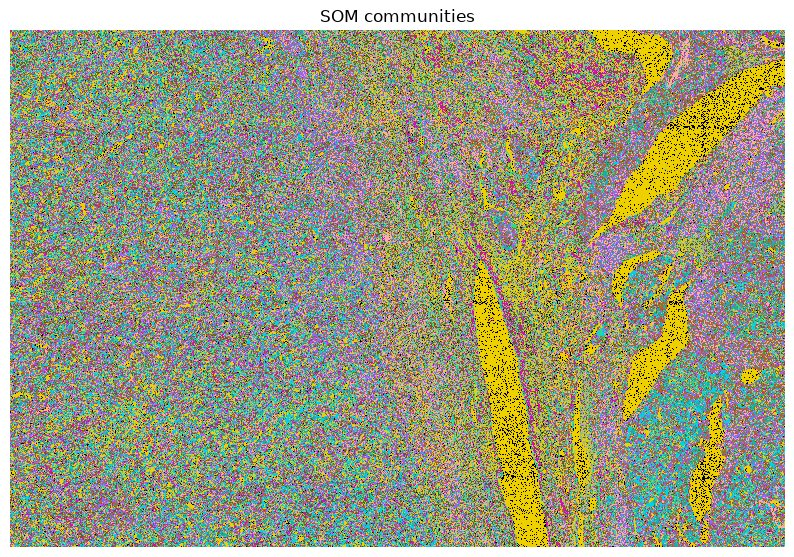

In [4]:
background_image = sdata.labels["som_communities"].values
n_communities = int(background_image.max())
print(f"{n_communities} SOM communities (plus background=0)")

rng = np.random.default_rng(0)
colors = rng.random((n_communities + 1, 3))
colors[0] = [0, 0, 0]  # background
som_cmap = mcolors.ListedColormap(colors)

plt.figure(figsize=(10, 10))
plt.imshow(background_image, cmap=som_cmap, interpolation="nearest")
plt.title("SOM communities")
plt.axis("off")
plt.show()

10 SOM communities (plus background=0)


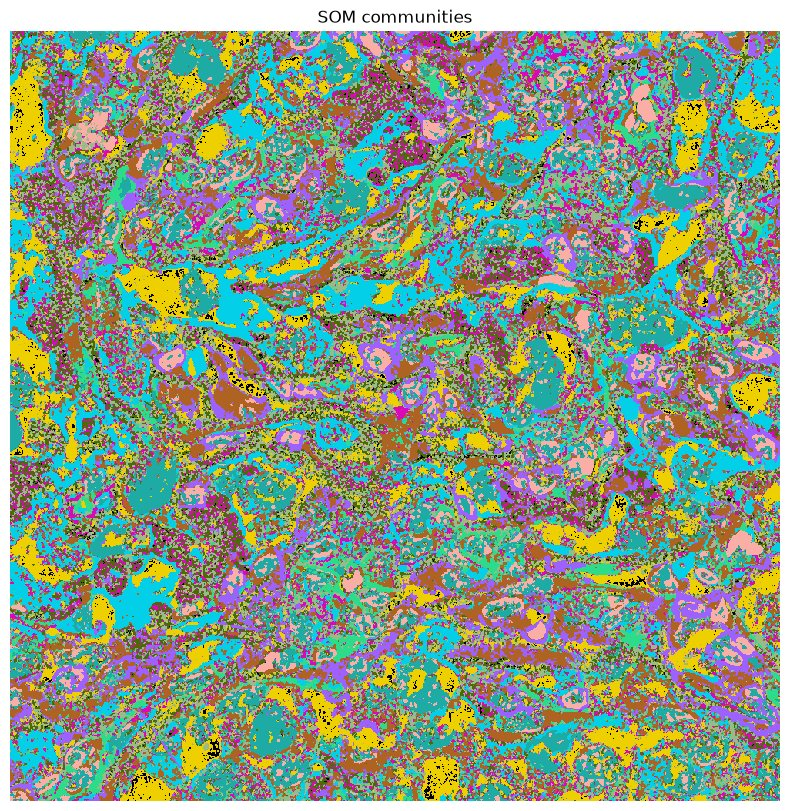

In [5]:
background_image = sdata.labels["som_communities"].values
n_communities = int(background_image.max())
print(f"{n_communities} SOM communities (plus background=0)")

rng = np.random.default_rng(0)
colors = rng.random((n_communities + 1, 3))
colors[0] = [0, 0, 0]  # background
som_cmap = mcolors.ListedColormap(colors)

plt.figure(figsize=(10, 10))
plt.imshow(background_image[0:1000, 0:1000], cmap=som_cmap, interpolation="nearest")
plt.title("SOM communities")
plt.axis("off")
plt.show()

## Per-community mean channel intensities

In [6]:
df_intensities = pd.read_csv(
    os.path.join(figures_path, "som_community_mean_intensities.csv"), index_col=0
).sort_index()
df_intensities

,DAPI,ATP1A1/CD45/E-Cadherin,18S,alphaSMA/Vimentin,Blue background,Green background,Yellow background,Red background,CD4,CD20,...,CD45RO,Ki-67,Beta-catenin,CD31,PTEN,PanCK,Vimentin,alphaSMA,CD45,E-Cadherin
community_id,,,,,,,,,,,,,,,,,,,,,
1,19.338219,33.087054,39.871909,109.106288,31.787216,3.418944,3.327809,21.426455,99.418910,98.886991,...,98.656602,102.176116,100.469908,99.997444,127.779364,117.736755,233.431125,103.877416,106.790210,106.806553
2,13.295807,15.257942,9.086318,6.893411,23.768469,2.768472,2.641353,22.575008,100.162312,98.756760,...,98.735878,97.784438,103.440347,100.180442,108.461220,98.279075,106.626248,100.025394,101.831220,99.556861
3,4.054953,3.234845,1.934306,2.110457,7.867761,1.304565,0.694799,11.279814,98.820913,98.999120,...,99.041318,98.704208,99.078359,98.790684,100.733386,98.425833,101.701593,98.677276,100.257772,98.228012
4,18.418117,22.094756,17.549332,20.023882,30.979187,3.302294,3.552206,25.004439,98.665150,99.009728,...,98.669808,97.154183,99.933685,99.766833,118.707493,97.930799,116.009474,116.636042,102.338237,101.955036
5,36.210657,34.915705,35.363049,19.777563,37.196955,3.934361,3.952762,25.167265,98.780531,98.834235,...,98.828574,98.967571,103.394026,122.508583,145.198794,99.553645,122.720207,101.932326,105.070316,103.596967
6,14.621894,9.963660,6.272436,4.147009,25.247515,2.665362,2.632593,23.193205,95.643931,98.940524,...,98.712711,96.999707,96.494591,98.981031,104.792227,97.748929,103.338728,99.065774,101.269983,98.387343
7,162.257792,18.182831,13.116700,7.509840,48.095619,4.922296,5.632952,24.626417,97.084800,98.834898,...,98.115558,100.862588,97.641010,99.074606,113.053109,97.778266,108.055958,99.301692,103.147088,100.769705
8,29.523686,87.660250,23.844903,10.919085,28.686049,3.141449,3.160736,22.671419,103.372534,99.765458,...,104.814000,98.830494,99.204564,101.245819,112.066886,98.103570,111.460275,100.763516,146.923261,106.183671
9,333.165102,37.464641,21.015423,15.234809,81.723149,7.919663,9.960223,33.636869,97.507879,98.891503,...,99.714567,97.358553,97.061426,99.811618,113.190328,97.155254,117.920284,99.714256,113.911651,103.415354


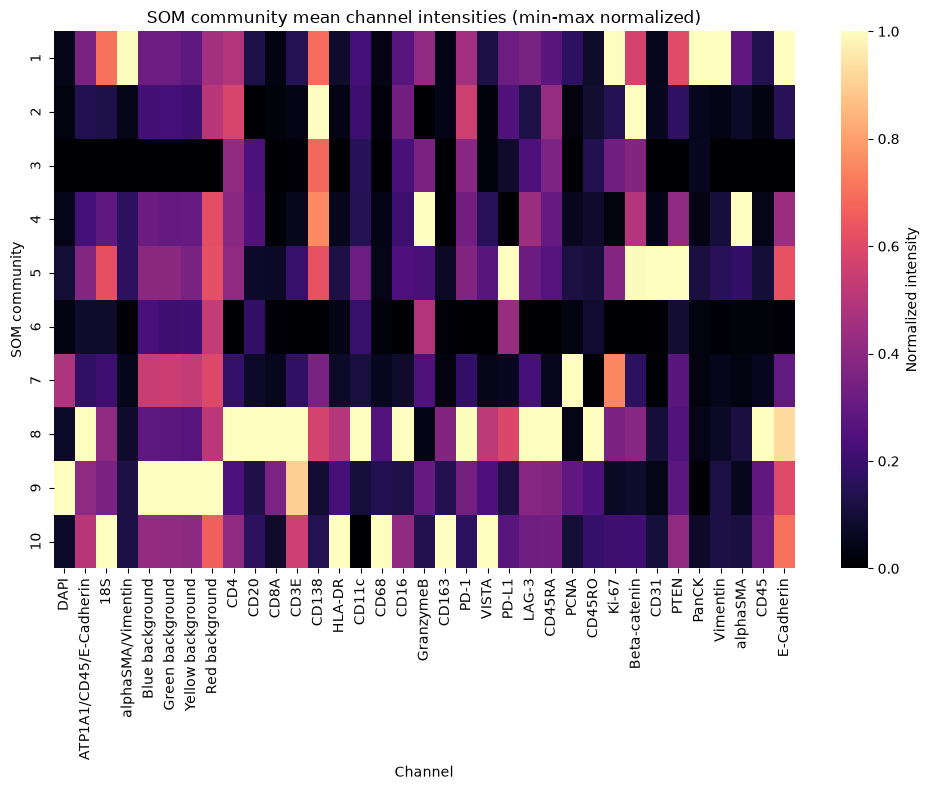

In [7]:
norm_intensities = (df_intensities - df_intensities.min()) / (
    df_intensities.max() - df_intensities.min() + 1e-9
)

plt.figure(figsize=(10, 8))
sns.heatmap(norm_intensities, cmap="magma", cbar_kws={"label": "Normalized intensity"})
plt.title("SOM community mean channel intensities (min-max normalized)")
plt.xlabel("Channel")
plt.ylabel("SOM community")
plt.tight_layout()
plt.show()

## Transcript counts per community

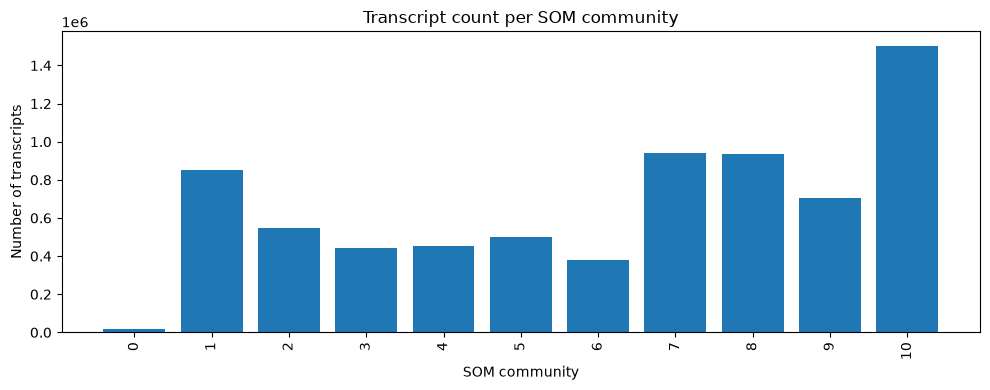

In [8]:
counts = pd.read_csv(
    os.path.join(figures_path, "som_community_transcript_counts.csv"), index_col=0
).sort_index()

plt.figure(figsize=(10, 4))
plt.bar(counts.index.astype(str), counts["n_transcripts"])
plt.xlabel("SOM community")
plt.ylabel("Number of transcripts")
plt.title("Transcript count per SOM community")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Spatial QC: transcripts colored by SOM community

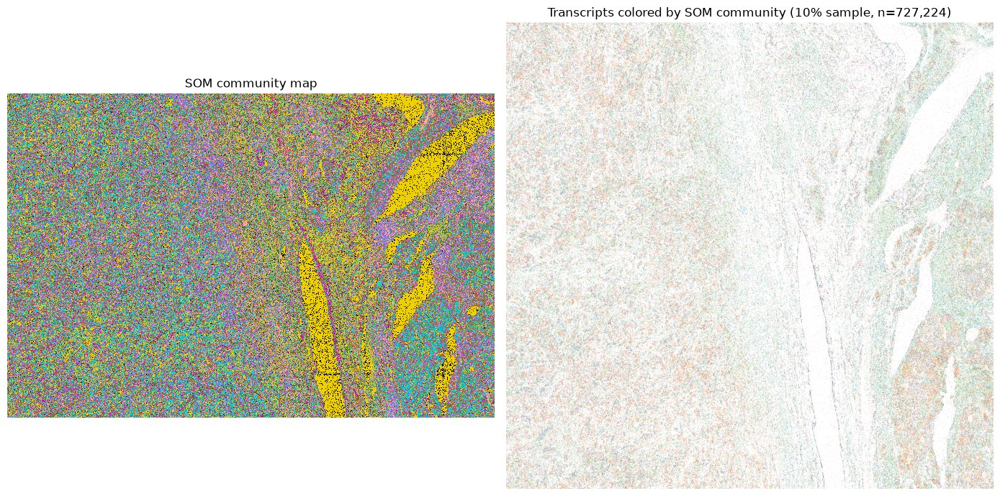

In [9]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# 1. Calculate min/max bounds before heavy sampling
minx, maxx = sdata.points["transcripts"]["x"].min().compute(), sdata.points["transcripts"]["x"].max().compute()
miny, maxy = sdata.points["transcripts"]["y"].min().compute(), sdata.points["transcripts"]["y"].max().compute()

# 2. Subsample 10% AT THE SOURCE to avoid loading everything into RAM
# (If dask object support fraction sampling, otherwise compute only a fraction)
transcripts_dask = sdata.points["transcripts"]
sample = transcripts_dask.sample(frac=0.10, random_state=0).compute().copy()

# 3. Scale coordinates efficiently
img_h, img_w = background_image.shape
mfx = img_w / (maxx - minx)
mfy = img_h / (maxy - miny)

sample["x_scaled"] = (sample["x"] - minx) * mfx
sample["y_scaled"] = (sample["y"] - miny) * mfy

# 4. Map colors fast using category codes instead of loop lookups
unique_ids = sorted(sample["som_community"].unique())
palette = mpl.colormaps["tab20"].resampled(max(len(unique_ids), 1))
color_map = {cid: palette(i % 20) for i, cid in enumerate(unique_ids)}

# Convert color mapping directly to array
colors = sample["som_community"].map(color_map).to_numpy()

# 5. Fast Lightweight Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)

axes[0].imshow(background_image, cmap=som_cmap, interpolation="nearest")
axes[0].set_title("SOM community map")
axes[0].axis("off")

# Optimized scatter: rasterized=True keeps vector backend light, 
# edgecolors='none' speeds up rendering dramatically
axes[1].scatter(
    sample["x_scaled"], 
    sample["y_scaled"],
    c=colors, 
    s=0.2, 
    alpha=0.4,
    edgecolors='none',
    rasterized=True  
)
axes[1].set_ylim(img_h, 0)
axes[1].set_xlim(0, img_w)
axes[1].set_title(f"Transcripts colored by SOM community (10% sample, n={len(sample):,})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

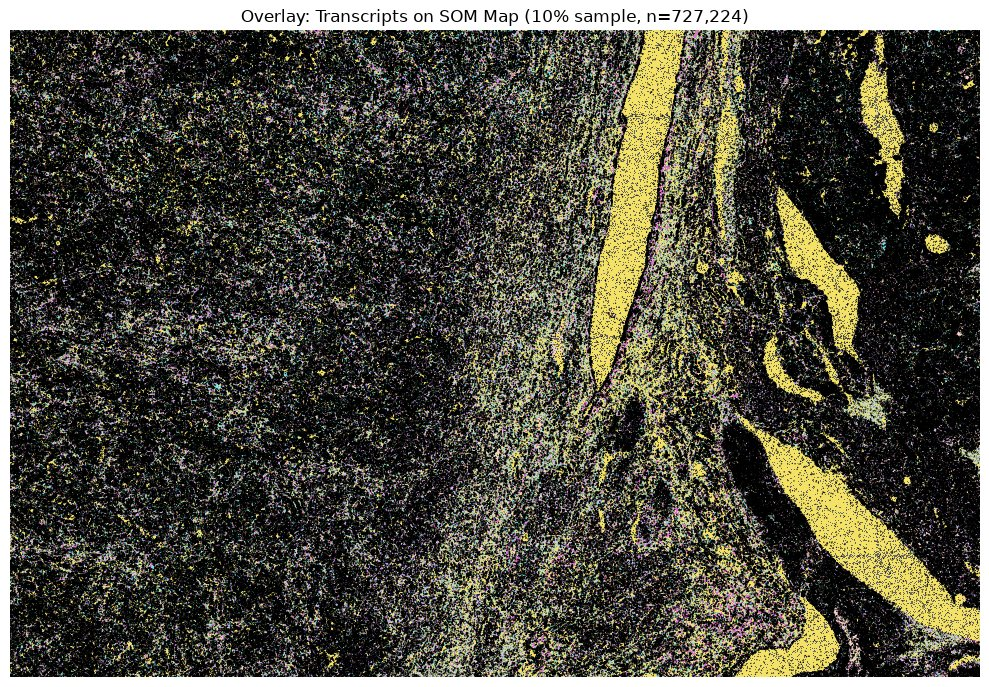

In [10]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# 1. Calculate min/max bounds before heavy sampling
minx, maxx = sdata.points["transcripts"]["x"].min().compute(), sdata.points["transcripts"]["x"].max().compute()
miny, maxy = sdata.points["transcripts"]["y"].min().compute(), sdata.points["transcripts"]["y"].max().compute()

# 2. Subsample 10%
transcripts_dask = sdata.points["transcripts"]
sample = transcripts_dask.sample(frac=0.10, random_state=0).compute().copy()

# 3. Scale coordinates to pixels
img_h, img_w = background_image.shape
mfx = img_w / (maxx - minx)
mfy = img_h / (maxy - miny)

sample["x_scaled"] = (sample["x"] - minx) * mfx
sample["y_scaled"] = (sample["y"] - miny) * mfy

# 4. Map colors
unique_ids = sorted(sample["som_community"].unique())
palette = mpl.colormaps["tab20"].resampled(max(len(unique_ids), 1))
color_map = {cid: palette(i % 20) for i, cid in enumerate(unique_ids)}
colors = sample["som_community"].map(color_map).to_numpy()

# 5. Combined Overlay Plot
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: Background map
ax.imshow(background_image, cmap=som_cmap, interpolation="nearest", alpha=0.6)

# Layer 2: Transcripts scatter overlay
ax.scatter(
    sample["x_scaled"], 
    sample["y_scaled"],
    c='black', 
    s=1, 
    alpha=0.9,
    edgecolors='none',
    rasterized=True  
)

ax.set_ylim(0, img_h)
ax.set_xlim(0, img_w)
ax.set_title(f"Overlay: Transcripts on SOM Map (10% sample, n={len(sample):,})")
ax.axis("off")

plt.tight_layout()
plt.show()

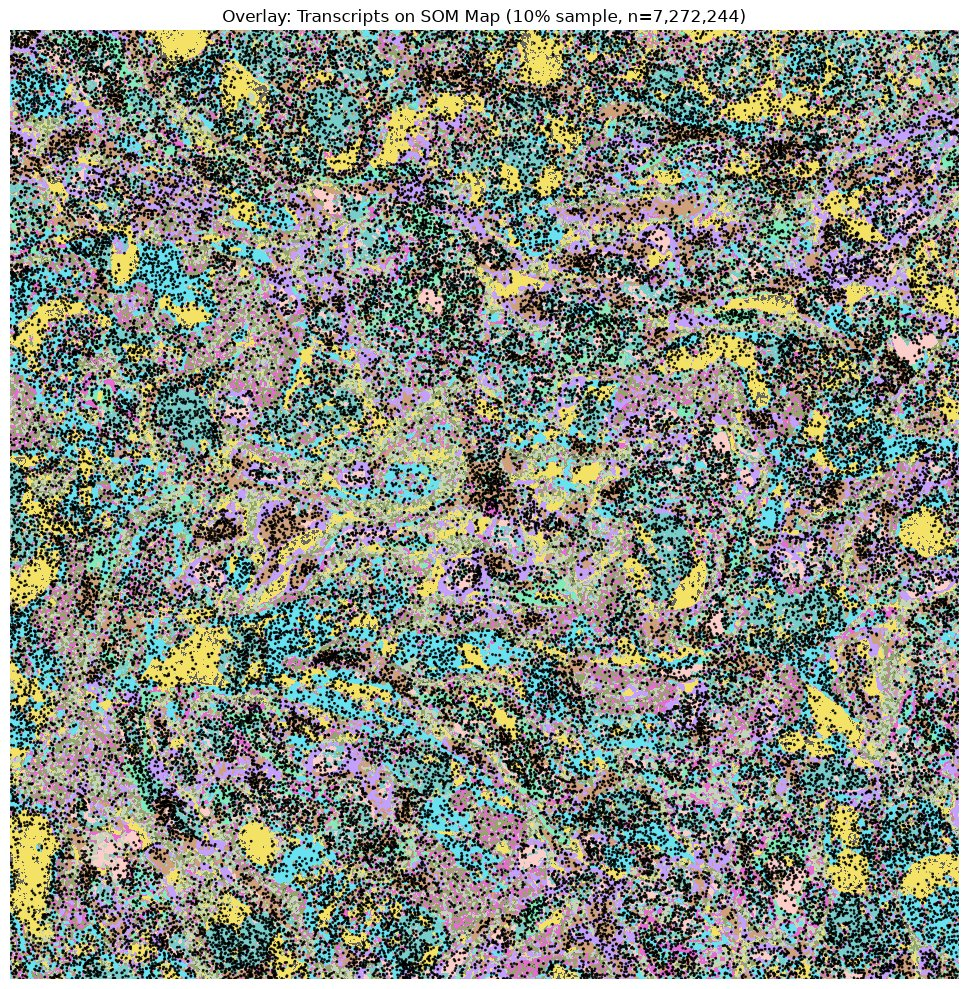

In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# 1. Calculate min/max bounds before heavy sampling
minx, maxx = sdata.points["transcripts"]["x"].min().compute(), sdata.points["transcripts"]["x"].max().compute()
miny, maxy = sdata.points["transcripts"]["y"].min().compute(), sdata.points["transcripts"]["y"].max().compute()

# 2. Subsample 10%
transcripts_dask = sdata.points["transcripts"]
sample = transcripts_dask.sample(frac=1.0, random_state=0).compute().copy()

# 3. Scale coordinates to pixels
img_h, img_w = background_image.shape
mfx = img_w / (maxx - minx)
mfy = img_h / (maxy - miny)

sample["x_scaled"] = (sample["x"] - minx) * mfx
sample["y_scaled"] = (sample["y"] - miny) * mfy

# 4. Map colors
unique_ids = sorted(sample["som_community"].unique())
palette = mpl.colormaps["tab20"].resampled(max(len(unique_ids), 1))
color_map = {cid: palette(i % 20) for i, cid in enumerate(unique_ids)}
colors = sample["som_community"].map(color_map).to_numpy()

# 5. Combined Overlay Plot
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: Background map
ax.imshow(background_image, cmap=som_cmap, interpolation="nearest", alpha=0.6)

# Layer 2: Transcripts scatter overlay
ax.scatter(
    sample["x_scaled"], 
    sample["y_scaled"],
    c='black', 
    s=4, 
    alpha=0.9,
    edgecolors='none',
    rasterized=True  
)

ax.set_ylim(0, 1000)
ax.set_xlim(0, 1000)
ax.set_title(f"Overlay: Transcripts on SOM Map (10% sample, n={len(sample):,})")
ax.axis("off")

plt.tight_layout()
plt.show()

/tmp/ipykernel_478660/4207130936.py:39: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  roi_shapes.boundary.plot(


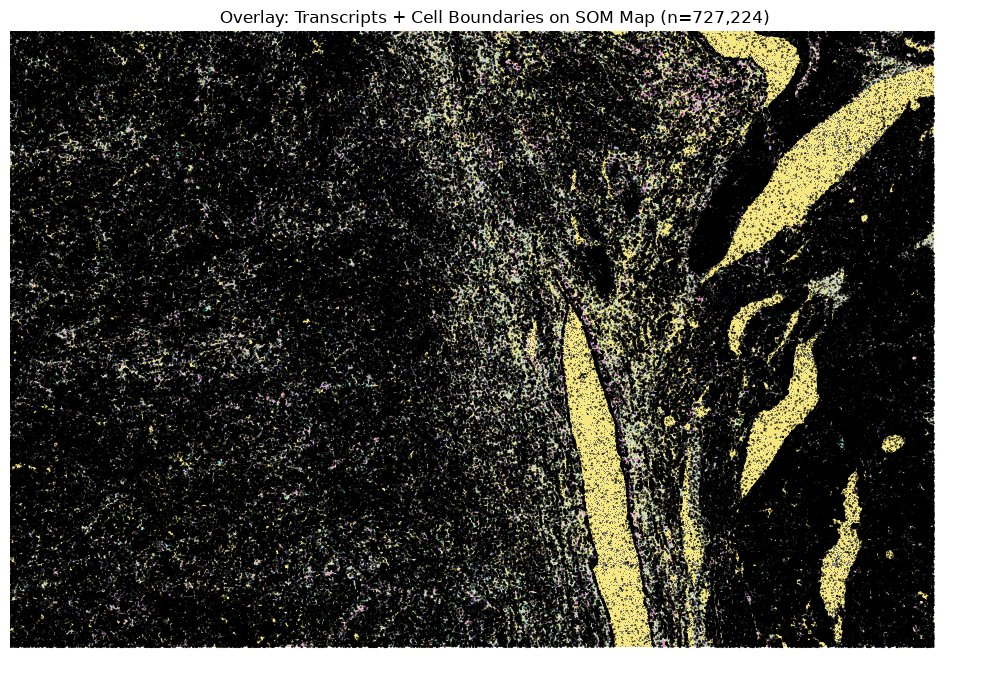

In [12]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# 1. Calculate min/max bounds before heavy sampling
minx, maxx = sdata.points["transcripts"]["x"].min().compute(), sdata.points["transcripts"]["x"].max().compute()
miny, maxy = sdata.points["transcripts"]["y"].min().compute(), sdata.points["transcripts"]["y"].max().compute()

# 2. Subsample transcripts & scale to pixels
transcripts_dask = sdata.points["transcripts"]
sample = transcripts_dask.sample(frac=0.10, random_state=0).compute().copy()

img_h, img_w = background_image.shape
mfx = img_w / (maxx - minx)
mfy = img_h / (maxy - miny)

sample["x_scaled"] = (sample["x"] - minx) * mfx
sample["y_scaled"] = (sample["y"] - miny) * mfy

# 3. Load and crop cell_boundaries shapes to ROI
cell_boundaries = sdata.shapes["cell_boundaries"]

# If cell_boundaries are stored in physical µm coordinates, map spatial slice bounds accordingly:
# (If they are already in pixel units, use 0:1000 directly)
roi_shapes = cell_boundaries.cx[0:1000, 0:1000]

# 4. Color mapping for scatter
unique_ids = sorted(sample["som_community"].unique())
palette = mpl.colormaps["tab20"].resampled(max(len(unique_ids), 1))
color_map = {cid: palette(i % 20) for i, cid in enumerate(unique_ids)}
colors = sample["som_community"].map(color_map).to_numpy()

# 5. Combined Overlay Plot
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: Background map
ax.imshow(background_image, cmap=som_cmap, interpolation="nearest", alpha=0.5)

# Layer 2: Vector Cell Boundaries (outlines)
roi_shapes.boundary.plot(
    ax=ax,
    color="blue",       # White outlines contrast well over colored backgrounds
    linewidth=1.0,
    alpha=0.8
)

# Layer 3: Transcripts scatter overlay
ax.scatter(
    sample["x_scaled"], 
    sample["y_scaled"],
    c='black', 
    s=2, 
    alpha=0.7,
    edgecolors='none',
    rasterized=True  
)

#ax.set_ylim( 0,1000)
#ax.set_xlim(0, 1000)
ax.set_title(f"Overlay: Transcripts + Cell Boundaries on SOM Map (n={len(sample):,})")
ax.axis("off")

plt.tight_layout()
plt.show()

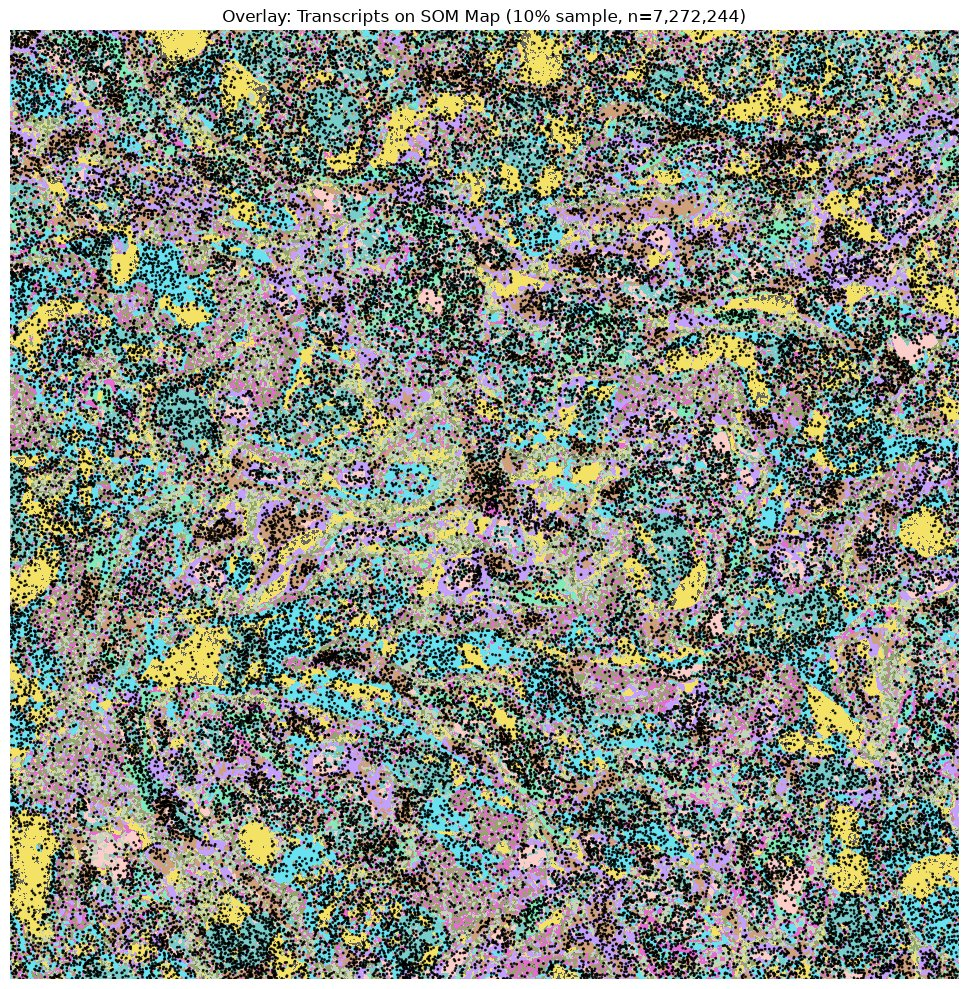

In [13]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# 1. Calculate min/max bounds before heavy sampling
minx, maxx = sdata.points["transcripts"]["x"].min().compute(), sdata.points["transcripts"]["x"].max().compute()
miny, maxy = sdata.points["transcripts"]["y"].min().compute(), sdata.points["transcripts"]["y"].max().compute()

# 2. Subsample 10%
transcripts_dask = sdata.points["transcripts"]
sample = transcripts_dask.sample(frac=1.0, random_state=0).compute().copy()

# 3. Scale coordinates to pixels
img_h, img_w = background_image.shape
mfx = img_w / (maxx - minx)
mfy = img_h / (maxy - miny)

sample["x_scaled"] = (sample["x"] - minx) * mfx
sample["y_scaled"] = (sample["y"] - miny) * mfy

# 4. Map colors
unique_ids = sorted(sample["som_community"].unique())
palette = mpl.colormaps["tab20"].resampled(max(len(unique_ids), 1))
color_map = {cid: palette(i % 20) for i, cid in enumerate(unique_ids)}
colors = sample["som_community"].map(color_map).to_numpy()

# 5. Combined Overlay Plot
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: Background map
ax.imshow(background_image, cmap=som_cmap, interpolation="nearest", alpha=0.6)

# Layer 2: Transcripts scatter overlay
ax.scatter(
    sample["x_scaled"], 
    sample["y_scaled"],
    c='black', 
    s=4, 
    alpha=0.9,
    edgecolors='none',
    rasterized=True  
)

ax.set_ylim(0, 1000)
ax.set_xlim(0, 1000)
ax.set_title(f"Overlay: Transcripts on SOM Map (10% sample, n={len(sample):,})")
ax.axis("off")

plt.tight_layout()
plt.show()

## Localization profile per community

Mean of `extracellular` / `overlaps_cell` / `overlaps_nucleus` for transcripts in each SOM community (background community 0 excluded).

In [14]:
transcripts=sdata['transcripts'].compute()

In [15]:
transcripts.loc[transcripts['overlaps_cell']==True,'point_source']='Intracellular'

In [16]:
transcripts['enrichment_class'].unique()

<ArrowStringArray>
['Intracellular', 'High Density', 'Moderate Density', 'Background']
Length: 4, dtype: string

In [17]:
import numpy as np

# 1. Define conditions in order of priority
conditions = [
    transcripts["overlaps_cell"] == True,
    transcripts["extracellular"] == False,
    transcripts["enrichment_class"] == "High Density",
]

# 2. Define corresponding labels for each condition
choices = [
    "Intracellular",
    "Cell-like",
    "High Density",
]

# 3. Apply logic (default fallback is 'Other')
transcripts["transcript_type"] = np.select(conditions, choices, default="Other")

# Optional: Convert to categorical for optimized memory & plotting
transcripts["transcript_type"] = transcripts["transcript_type"].astype("category")

# Inspect the resulting distribution
print(transcripts["transcript_type"].value_counts(dropna=False))

transcript_type
Intracellular    5757156
Cell-like        1078751
High Density      237157
Other             199180
Name: count, dtype: int64


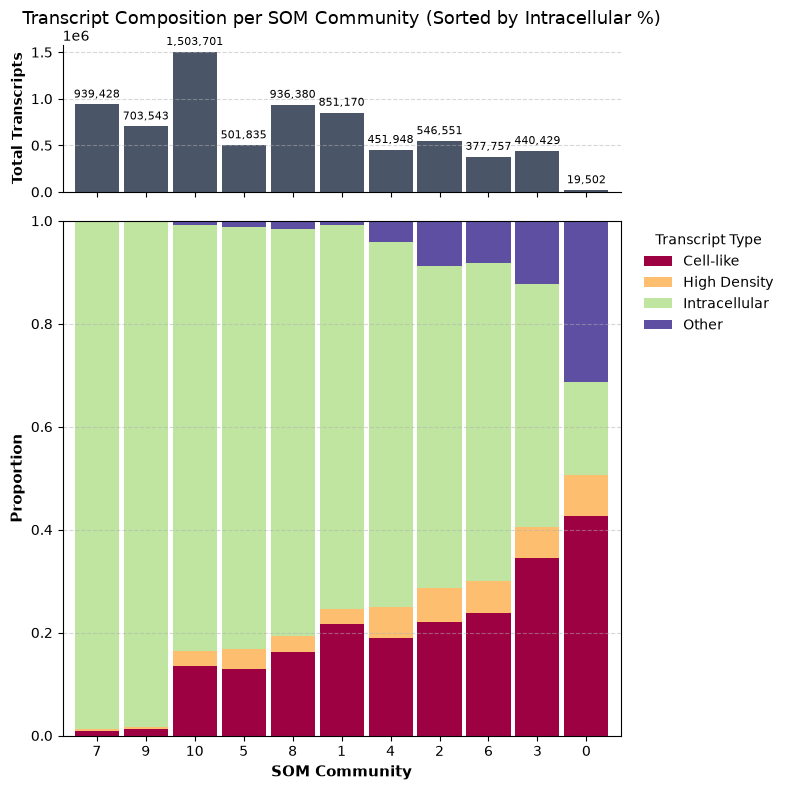

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Compute proportions and total counts per SOM community
ct_prop = pd.crosstab(
    transcripts["som_community"], 
    transcripts["transcript_type"], 
    normalize="index"
)
totals = transcripts["som_community"].value_counts()

# 2. Sort by descending proportion of 'Intracellular'
if "Intracellular" in ct_prop.columns:
    ct_prop = ct_prop.sort_values(by="Intracellular", ascending=False)
else:
    ct_prop = ct_prop.sort_values(by=ct_prop.columns[0], ascending=False)

# Reorder totals to match the sorted index
totals = totals.reindex(ct_prop.index)

# 3. Create Subplots (Top: Total Counts, Bottom: Stacked Proportions)
fig, (ax_top, ax_bottom) = plt.subplots(
    nrows=2, 
    ncols=1, 
    figsize=(max(8, len(ct_prop) * 0.45), 8), 
    sharex=True, 
    gridspec_kw={"height_ratios": [1, 3.5]}
)

# --- Top Plot: Total Transcript Counts ---
bars = ax_top.bar(
    [str(x) for x in ct_prop.index], 
    totals.values, 
    color="#4A5568", 
    width=0.9
)
ax_top.set_ylabel("Total Transcripts", fontsize=10, fontweight="bold")
ax_top.set_title("Transcript Composition per SOM Community (Sorted by Intracellular %)", fontsize=13, pad=15)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)
ax_top.grid(axis="y", linestyle="--", alpha=0.5)

# Add numeric count values above top bars
for bar in bars:
    height = bar.get_height()
    ax_top.annotate(
        f"{height:,}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center", 
        va="bottom",
        fontsize=8,
        rotation=45 if len(ct_prop) > 15 else 0
    )

# --- Bottom Plot: 100% Stacked Bar Plot ---
ct_prop.plot(
    kind="bar", 
    stacked=True, 
    ax=ax_bottom, 
    width=0.9, 
    colormap="Spectral"
)

ax_bottom.set_xlabel("SOM Community", fontsize=11, fontweight="bold")
ax_bottom.set_ylabel("Proportion", fontsize=11, fontweight="bold")
ax_bottom.set_ylim(0, 1.0)
ax_bottom.legend(title="Transcript Type", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax_bottom.grid(axis="y", linestyle="--", alpha=0.5)
ax_bottom.tick_params(axis="x", rotation=0 if len(ct_prop) <= 15 else 45)

plt.tight_layout()
plt.show()

In [19]:
sdata['image_intensity_per_transcript']

AnnData object with n_obs × n_vars = 7272244 × 35
    obs: 'gene'
    obsm: 'spatial'

In [20]:
sdata['transcripts'].columns

Index(['x', 'y', 'z', 'gene', 'cell_id', 'fov_name', 'qv', 'codeword_index',
       'is_gene', 'nucleus_distance', 'overlaps_nucleus', 'transcript_id',
       'codeword_category', 'control_probe', 'overlaps_cell',
       'enrichment_class', 'density_similarity_score',
       'enrichment_over_random', 'local_count_in_radius', 'closest_cell_type',
       'cosine_similarity', 'prob_is_urna', 'extracellular',
       'cosine_sim_stainings', 'prob_is_urna_stainings',
       'extracellular_stainings', 'point_source', 'structure_id',
       'som_community'],
      dtype='object')

In [21]:
som_labels = {
    7: "Proliferating Cells",
    9: "Nuclear-Rich Density",
    10: "Macrophages / Myeloid",
    5: "Endothelial / Vascular Stroma",
    8: "T-Cell / Lymphocyte Infiltrate",
    1: "Epithelial / Tumor Stroma",
    4: "Activated Stroma (alphaSMA+)",
    2: "Plasma Cells (CD138+)",
    6: "Mixed Interstitial Stroma",
    3: "Low-Signal Matrix",
    0: "Background"
}

transcripts["som_label"] = transcripts["som_community"].map(som_labels)

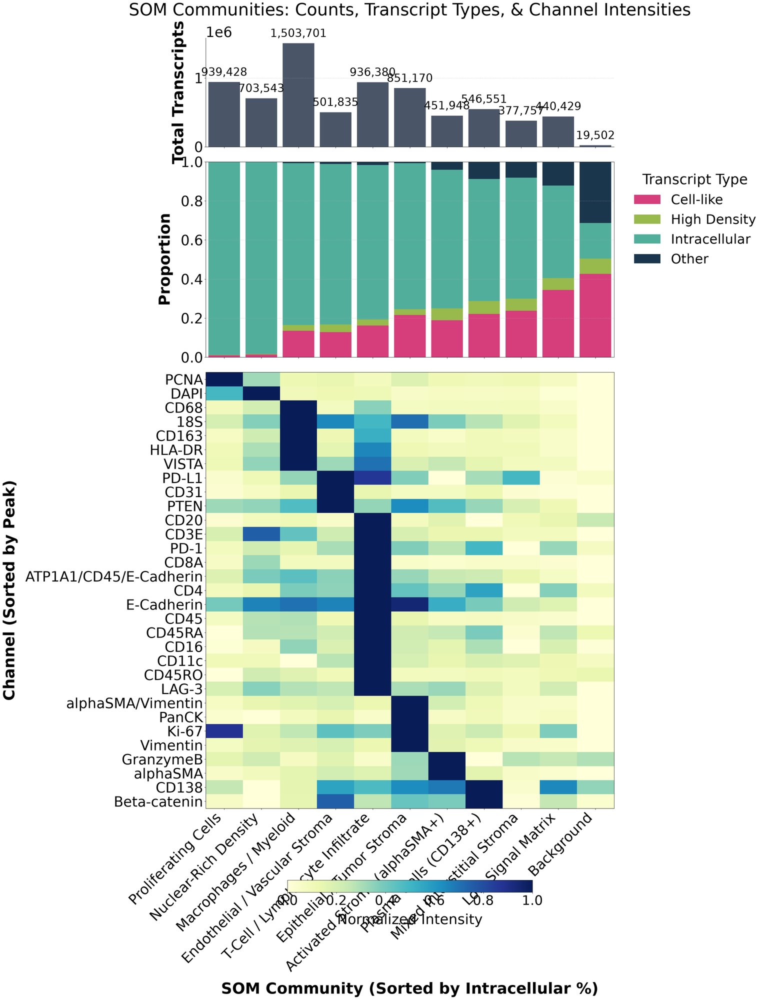

In [22]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# -------------------------------------------------------------------------
# Global Style Settings (Fontsize 42)
# -------------------------------------------------------------------------
FONT_SIZE = 42
plt.rcParams.update(
    {
        "font.size": FONT_SIZE,
        "axes.titlesize": FONT_SIZE + 4,
        "axes.labelsize": FONT_SIZE,
        "xtick.labelsize": FONT_SIZE - 4,
        "ytick.labelsize": FONT_SIZE - 4,
        "legend.fontsize": FONT_SIZE - 6,
        "legend.title_fontsize": FONT_SIZE - 4,
    }
)

saving_path = Path(
    "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc"
)

# Custom color palette mapping for transcript types
type_color_map = {
    "Intracellular": "#51ae9b",
    "Cell-like": "#d53e7a",
    "High Density": "#98b94c",
    "Other": "#1a364d",
}

# -------------------------------------------------------------------------
# 1. Compute Channel Intensities per SOM Community from sdata (Including 0)
# -------------------------------------------------------------------------
intensity_adata = sdata.tables["image_intensity_per_transcript"]

# Convert AnnData .X to DataFrame safely
if hasattr(intensity_adata.X, "toarray"):
    intensity_df = pd.DataFrame(
        intensity_adata.X.toarray(), columns=intensity_adata.var_names
    )
else:
    intensity_df = pd.DataFrame(
        intensity_adata.X, columns=intensity_adata.var_names
    )

# Assign som_community matching row index
intensity_df["som_community"] = transcripts["som_community"].values

# Compute mean channel intensities for ALL communities (including 0)
df_intensities = intensity_df.groupby("som_community").mean()

# -------------------------------------------------------------------------
# 2. Data Preparation & Sorting
# -------------------------------------------------------------------------
# Compute proportions and total counts per SOM community
ct_prop = pd.crosstab(
    transcripts["som_community"],
    transcripts["transcript_type"],
    normalize="index",
)
totals = transcripts["som_community"].value_counts()

# Sort SOM Communities by descending proportion of 'Intracellular'
sort_col = (
    "Intracellular" if "Intracellular" in ct_prop.columns else ct_prop.columns[0]
)
ct_prop = ct_prop.sort_values(by=sort_col, ascending=False)

sorted_ids = ct_prop.index
totals = totals.reindex(sorted_ids)

# Filter out background channels
clean_channels = [
    c for c in df_intensities.columns if "background" not in c.lower()
]

# Align all communities (including 0) and Min-Max normalize
df_intensities_sorted = df_intensities.reindex(sorted_ids)[clean_channels]
norm_intensities = (df_intensities_sorted - df_intensities_sorted.min()) / (
    df_intensities_sorted.max() - df_intensities_sorted.min() + 1e-9
)

# Transpose so channels are rows, SOM communities are columns
heatmap_data = norm_intensities.T

# Sort Channels by where they peak across ALL communities
peak_community_idx = heatmap_data.idxmax(axis=1).map(
    lambda x: list(sorted_ids).index(x)
)
sorted_channels = (
    heatmap_data.assign(peak_idx=peak_community_idx)
    .sort_values("peak_idx", ascending=True)
    .index
)
heatmap_data = heatmap_data.loc[sorted_channels]

# -------------------------------------------------------------------------
# 3. Synchronized Plotting
# -------------------------------------------------------------------------
x_pos = np.arange(len(sorted_ids))
bar_width = 0.85

fig_width = max(20, len(sorted_ids) * 1.4)
fig_height = max(34, len(sorted_channels) * 0.9 + 18)

fig, (ax_top, ax_mid, ax_bot) = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(fig_width, fig_height),
    sharex=True,
    gridspec_kw={
        "height_ratios": [1, 1.8, 5.5],
        "hspace": 0.05,
    },  # Reduced vertical padding between panels
)

# --- TOP PANEL: Total Transcript Counts ---
bars = ax_top.bar(x_pos, totals.values, color="#4A5568", width=bar_width)
ax_top.set_ylabel("Total Transcripts", fontweight="bold", labelpad=20)
ax_top.set_title(
    "SOM Communities: Counts, Transcript Types, & Channel Intensities", pad=30
)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)
ax_top.grid(axis="y", linestyle="--", alpha=0.5)

# Annotate numbers on top of bars
for bar in bars:
    height = bar.get_height()
    ax_top.annotate(
        f"{height:,}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=FONT_SIZE - 12,
        rotation=35 if len(sorted_ids) > 12 else 0,
    )

# --- MIDDLE PANEL: 100% Stacked Bar Plot with Custom Colors ---
bottom_val = np.zeros(len(sorted_ids))

for col in ct_prop.columns:
    values = ct_prop[col].values
    bar_color = type_color_map.get(
        col, "#808080"
    )  # Fallback to gray if key is missing
    ax_mid.bar(
        x_pos,
        values,
        bottom=bottom_val,
        label=col,
        color=bar_color,
        width=bar_width,
    )
    bottom_val += values

ax_mid.set_ylabel("Proportion", fontweight="bold", labelpad=20)
ax_mid.set_ylim(0, 1.0)
ax_mid.legend(
    title="Transcript Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
ax_mid.grid(axis="y", linestyle="--", alpha=0.5)

# --- BOTTOM PANEL: Channel Intensities Heatmap ---
img = ax_bot.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlGnBu",
    extent=[-0.5, len(sorted_ids) - 0.5, len(sorted_channels) - 0.5, -0.5],
    interpolation="nearest",
)

# Y-Axis (Channels)
ax_bot.set_yticks(np.arange(len(sorted_channels)))
ax_bot.set_yticklabels(sorted_channels)
ax_bot.set_ylabel("Channel (Sorted by Peak)", fontweight="bold", labelpad=20)

# X-Axis (SOM Communities)
ax_bot.set_xticks(x_pos)
ax_bot.set_xticklabels(
    [som_labels.get(x, f"Community {x}") for x in sorted_ids],
    rotation=45,
    ha="right",
)
ax_bot.set_xlabel(
    "SOM Community (Sorted by Intracellular %)", fontweight="bold", labelpad=20
)

# Colorbar for Heatmap
cbar = fig.colorbar(
    img, ax=ax_bot, orientation="horizontal", pad=0.12, shrink=0.6
)
cbar.set_label("Normalized Intensity", fontsize=FONT_SIZE - 4, labelpad=15)
cbar.ax.tick_params(labelsize=FONT_SIZE - 6)

plt.savefig(
    os.path.join(saving_path, "som_communities_analysis_typecolors.pdf"),
    format="pdf",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

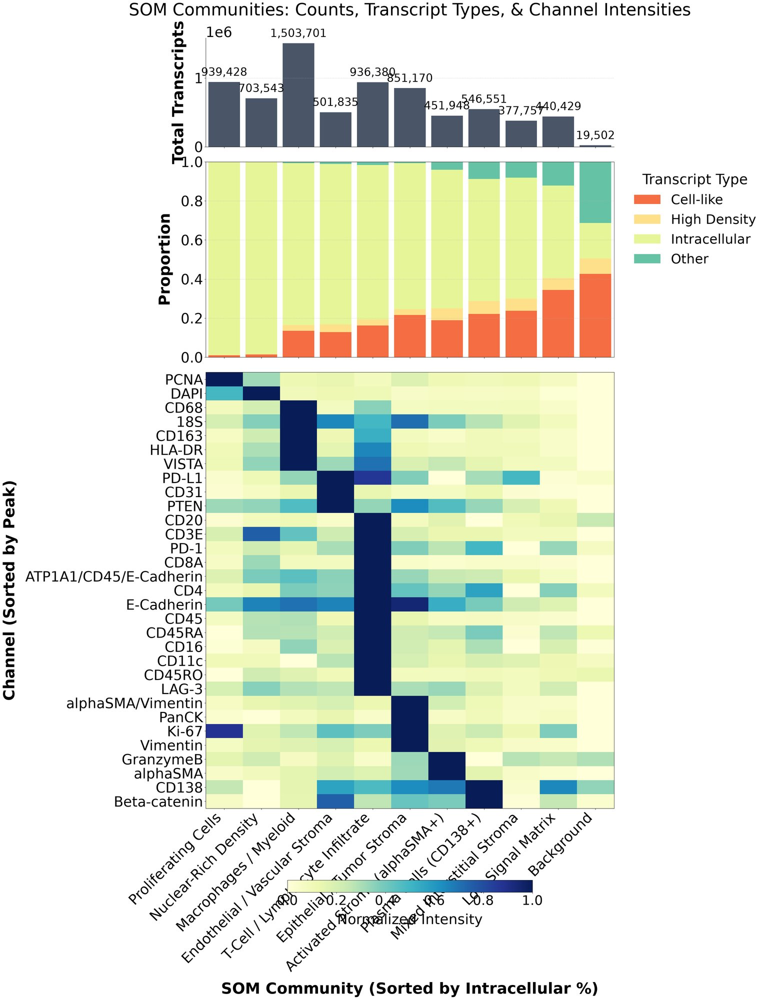

In [23]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

# -------------------------------------------------------------------------
# Global Style Settings (Fontsize 42)
# -------------------------------------------------------------------------
FONT_SIZE = 42
plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE + 4,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE - 4,
    "ytick.labelsize": FONT_SIZE - 4,
    "legend.fontsize": FONT_SIZE - 6,
    "legend.title_fontsize": FONT_SIZE - 4,
})

saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc")

# -------------------------------------------------------------------------
# 1. Compute Channel Intensities per SOM Community from sdata (Including 0)
# -------------------------------------------------------------------------
intensity_adata = sdata.tables["image_intensity_per_transcript"]

# Convert AnnData .X to DataFrame safely
if hasattr(intensity_adata.X, "toarray"):
    intensity_df = pd.DataFrame(intensity_adata.X.toarray(), columns=intensity_adata.var_names)
else:
    intensity_df = pd.DataFrame(intensity_adata.X, columns=intensity_adata.var_names)

# Assign som_community matching row index
intensity_df["som_community"] = transcripts["som_community"].values

# Compute mean channel intensities for ALL communities (including 0)
df_intensities = intensity_df.groupby("som_community").mean()

# -------------------------------------------------------------------------
# 2. Data Preparation & Sorting
# -------------------------------------------------------------------------
# Compute proportions and total counts per SOM community
ct_prop = pd.crosstab(
    transcripts["som_community"], 
    transcripts["transcript_type"], 
    normalize="index"
)
totals = transcripts["som_community"].value_counts()

# Sort SOM Communities by descending proportion of 'Intracellular'
sort_col = "Intracellular" if "Intracellular" in ct_prop.columns else ct_prop.columns[0]
ct_prop = ct_prop.sort_values(by=sort_col, ascending=False)

sorted_ids = ct_prop.index
totals = totals.reindex(sorted_ids)

# Filter out background channels
clean_channels = [c for c in df_intensities.columns if "background" not in c.lower()]

# Align all communities (including 0) and Min-Max normalize
df_intensities_sorted = df_intensities.reindex(sorted_ids)[clean_channels]
norm_intensities = (df_intensities_sorted - df_intensities_sorted.min()) / (
    df_intensities_sorted.max() - df_intensities_sorted.min() + 1e-9
)

# Transpose so channels are rows, SOM communities are columns
heatmap_data = norm_intensities.T

# Sort Channels by where they peak across ALL communities
peak_community_idx = heatmap_data.idxmax(axis=1).map(lambda x: list(sorted_ids).index(x))
sorted_channels = heatmap_data.assign(peak_idx=peak_community_idx).sort_values("peak_idx", ascending=True).index
heatmap_data = heatmap_data.loc[sorted_channels]

# -------------------------------------------------------------------------
# 3. Synchronized Plotting
# -------------------------------------------------------------------------
x_pos = np.arange(len(sorted_ids))
bar_width = 0.85

fig_width = max(20, len(sorted_ids) * 1.4)
fig_height = max(34, len(sorted_channels) * 0.9 + 18)

fig, (ax_top, ax_mid, ax_bot) = plt.subplots(
    nrows=3, 
    ncols=1, 
    figsize=(fig_width, fig_height), 
    sharex=True, 
    gridspec_kw={"height_ratios": [1, 1.8, 5.5], "hspace": 0.05}  # Reduced vertical padding between panels
)

# --- TOP PANEL: Total Transcript Counts ---
bars = ax_top.bar(x_pos, totals.values, color="#4A5568", width=bar_width)
ax_top.set_ylabel("Total Transcripts", fontweight="bold", labelpad=20)
ax_top.set_title("SOM Communities: Counts, Transcript Types, & Channel Intensities", pad=30)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)
ax_top.grid(axis="y", linestyle="--", alpha=0.5)

# Annotate numbers on top of bars
for bar in bars:
    height = bar.get_height()
    ax_top.annotate(
        f"{height:,}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center", 
        va="bottom",
        fontsize=FONT_SIZE - 12,
        rotation=35 if len(sorted_ids) > 12 else 0
    )

# --- MIDDLE PANEL: 100% Stacked Bar Plot ---
bottom_val = np.zeros(len(sorted_ids))
colors = sns.color_palette("Spectral", n_colors=len(ct_prop.columns))

for idx, col in enumerate(ct_prop.columns):
    values = ct_prop[col].values
    ax_mid.bar(x_pos, values, bottom=bottom_val, label=col, color=colors[idx], width=bar_width)
    bottom_val += values

ax_mid.set_ylabel("Proportion", fontweight="bold", labelpad=20)
ax_mid.set_ylim(0, 1.0)
ax_mid.legend(title="Transcript Type", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax_mid.grid(axis="y", linestyle="--", alpha=0.5)

# --- BOTTOM PANEL: Channel Intensities Heatmap ---
img = ax_bot.imshow(
    heatmap_data.values, 
    aspect="auto", 
    cmap="YlGnBu", 
    extent=[-0.5, len(sorted_ids) - 0.5, len(sorted_channels) - 0.5, -0.5],
    interpolation="nearest"
)

# Y-Axis (Channels)
ax_bot.set_yticks(np.arange(len(sorted_channels)))
ax_bot.set_yticklabels(sorted_channels)
ax_bot.set_ylabel("Channel (Sorted by Peak)", fontweight="bold", labelpad=20)

# X-Axis (SOM Communities)
ax_bot.set_xticks(x_pos)
ax_bot.set_xticklabels(
    [som_labels.get(x, f"Community {x}") for x in sorted_ids],
    rotation=45,
    ha="right",
)
ax_bot.set_xlabel("SOM Community (Sorted by Intracellular %)", fontweight="bold", labelpad=20)

# Colorbar for Heatmap
cbar = fig.colorbar(img, ax=ax_bot, orientation="horizontal", pad=0.12, shrink=0.6)
cbar.set_label("Normalized Intensity", fontsize=FONT_SIZE - 4, labelpad=15)
cbar.ax.tick_params(labelsize=FONT_SIZE - 6)

plt.savefig(os.path.join(saving_path, "som_communities_analysis_spectral.pdf"), format="pdf", dpi=300, bbox_inches="tight")
plt.show()

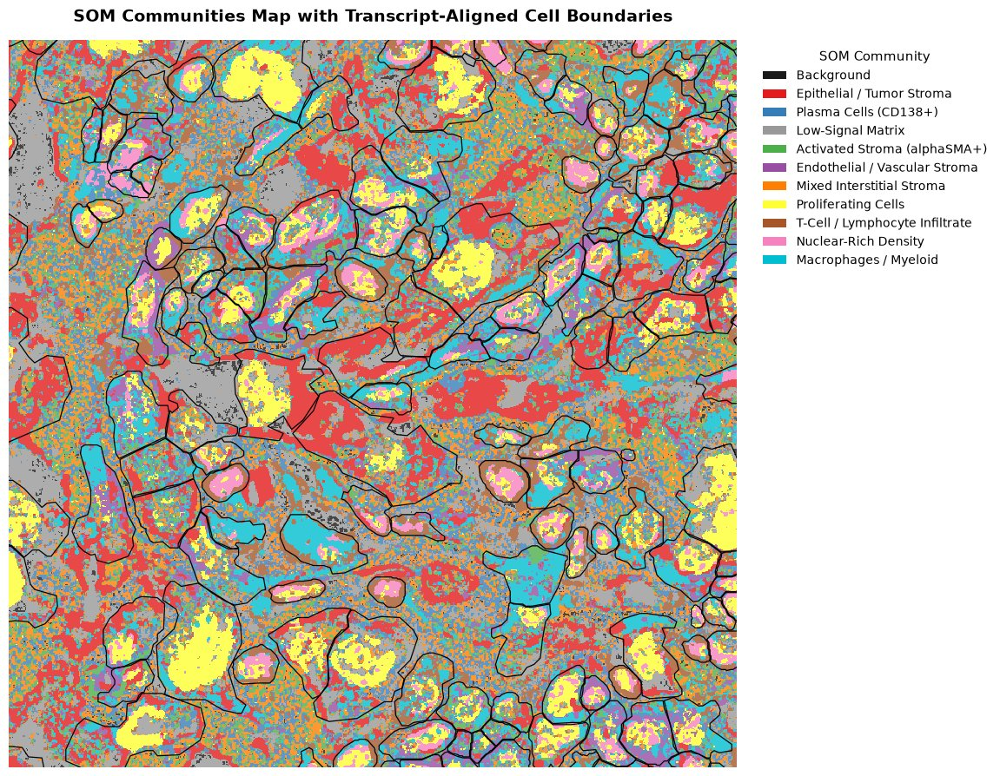

In [24]:
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import numpy as np

# -------------------------------------------------------------------------
# 0. SOM Label Assignment
# -------------------------------------------------------------------------
som_labels = {
    7: "Proliferating Cells",
    9: "Nuclear-Rich Density",
    10: "Macrophages / Myeloid",
    5: "Endothelial / Vascular Stroma",
    8: "T-Cell / Lymphocyte Infiltrate",
    1: "Epithelial / Tumor Stroma",
    4: "Activated Stroma (alphaSMA+)",
    2: "Plasma Cells (CD138+)",
    6: "Mixed Interstitial Stroma",
    3: "Low-Signal Matrix",
    0: "Background",
}

# -------------------------------------------------------------------------
# 1. Custom Group Color Specification
# -------------------------------------------------------------------------
unique_communities = sorted(np.unique(background_image))

# Defined explicit hex color mapping for each community ID
custom_colors = {
    0: "#1a1a1a",  # Background (Dark Neutral)
    1: "#e41a1c",  # Epithelial / Tumor Stroma
    2: "#377eb8",  # Plasma Cells (CD138+)
    3: "#999999",  # Low-Signal Matrix
    4: "#4daf4a",  # Activated Stroma (alphaSMA+)
    5: "#984ea3",  # Endothelial / Vascular Stroma
    6: "#ff7f00",  # Mixed Interstitial Stroma
    7: "#ffff33",  # Proliferating Cells
    8: "#a65628",  # T-Cell / Lymphocyte Infiltrate
    9: "#f781bf",  # Nuclear-Rich Density
    10: "#00bed1", # Macrophages / Myeloid
}

tab20 = mpl.colormaps["tab20"]

if custom_colors is None:
    color_map = {
        cid: mpl.colors.to_hex(tab20(i % 20))
        for i, cid in enumerate(unique_communities)
    }
else:
    color_map = {
        cid: custom_colors.get(cid, mpl.colors.to_hex(tab20(i % 20)))
        for i, cid in enumerate(unique_communities)
    }

label_map = (
    som_labels
    if "som_labels" in locals()
    else {cid: f"Community {cid}" for cid in unique_communities}
)

# Create a discrete colormap & normalization matching image values
som_cmap = ListedColormap([color_map[cid] for cid in unique_communities])
bounds = np.append(unique_communities, max(unique_communities) + 1) - 0.5
norm = BoundaryNorm(bounds, som_cmap.N)

# -------------------------------------------------------------------------
# 2. Process & Shift Cell Boundaries using Transcript Min/Max
# -------------------------------------------------------------------------
boundaries = sdata["cell_boundaries"]
if hasattr(boundaries, "compute"):
    boundaries = boundaries.compute()

# Extract transcripts object (handles both pandas and spatialdata/dask objects)
transcripts = sdata["transcripts"]
if hasattr(transcripts, "compute"):
    transcripts = transcripts.compute()

# Assign SOM label to transcripts if som_community column exists
if "som_community" in transcripts.columns:
    transcripts["som_label"] = transcripts["som_community"].map(som_labels)

# Compute minimums and maximums from transcript coordinates
t_minx = float(transcripts["x"].min())
t_maxx = float(transcripts["x"].max())
t_miny = float(transcripts["y"].min())
t_maxy = float(transcripts["y"].max())

# Translate polygon coordinates by subtracting transcript min_x and min_y
boundaries_shifted = boundaries.copy()
boundaries_shifted["geometry"] = boundaries.geometry.translate(
    xoff=-t_minx, yoff=-t_miny
)

# Scale using the transcript coordinate range
img_h, img_w = background_image.shape
mfx = img_w / (t_maxx - t_minx)
mfy = img_h / (t_maxy - t_miny)

boundaries_shifted["geometry"] = boundaries_shifted.geometry.scale(
    xfact=mfx, yfact=mfy, origin=(0, 0)
)

# -------------------------------------------------------------------------
# 3. Spatial ROI Filtering & Boundary Overlay
# -------------------------------------------------------------------------
xmin, xmax = 0, 700
ymin, ymax = 0, 700

# Filter boundaries within ROI bounds using GeoPandas .cx indexer
boundaries_roi = boundaries_shifted.cx[xmin:xmax, ymin:ymax].copy()

fig, ax = plt.subplots(figsize=(12, 10))

# Layer 1: Background image
ax.imshow(
    background_image,
    cmap=som_cmap,
    norm=norm,
    interpolation="nearest",
    alpha=0.8,
)

# Layer 2: Overlay ROI-filtered Boundaries
boundaries_roi.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.9,
    alpha=1.0,
)

# -------------------------------------------------------------------------
# 4. Set ROI & Clean Axis
# -------------------------------------------------------------------------
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymax, ymin)  # Inverted Y-axis to match spatial image coordinates

ax.set_title(
    "SOM Communities Map with Transcript-Aligned Cell Boundaries",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.axis("off")

# -------------------------------------------------------------------------
# 5. Matching Legend & Export
# -------------------------------------------------------------------------
legend_elements = [
    Patch(
        facecolor=color_map[cid],
        edgecolor="none",
        label=label_map.get(cid, f"Community {cid}"),
    )
    for cid in unique_communities
]

ax.legend(
    handles=legend_elements,
    title="SOM Community",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=10,
    title_fontsize=11,
)

plt.tight_layout()

if "saving_path" in locals() and saving_path is not None:
    plt.savefig(
        os.path.join(saving_path, "som_communities_with_boundaries.pdf"),
        format="pdf",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()

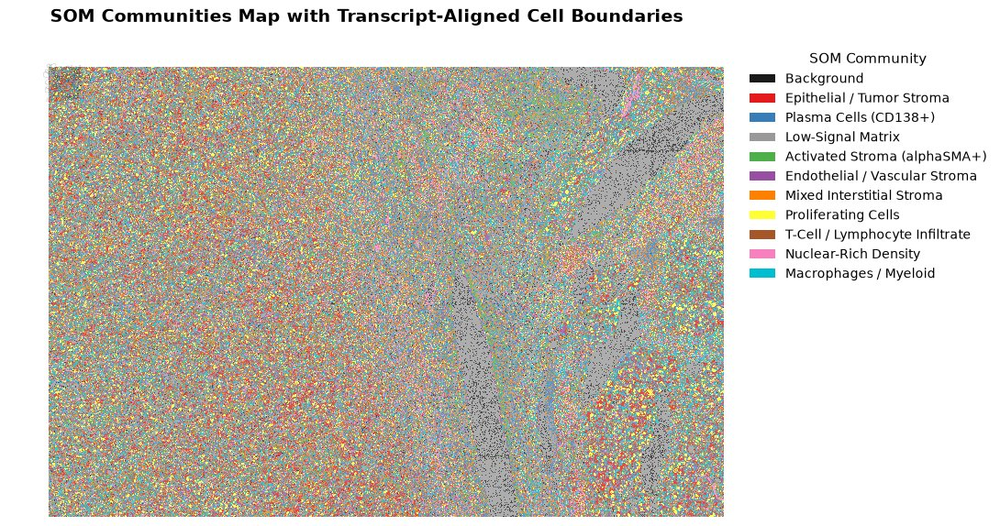

In [25]:
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import numpy as np

# -------------------------------------------------------------------------
# 0. SOM Label Assignment
# -------------------------------------------------------------------------
som_labels = {
    7: "Proliferating Cells",
    9: "Nuclear-Rich Density",
    10: "Macrophages / Myeloid",
    5: "Endothelial / Vascular Stroma",
    8: "T-Cell / Lymphocyte Infiltrate",
    1: "Epithelial / Tumor Stroma",
    4: "Activated Stroma (alphaSMA+)",
    2: "Plasma Cells (CD138+)",
    6: "Mixed Interstitial Stroma",
    3: "Low-Signal Matrix",
    0: "Background",
}

# -------------------------------------------------------------------------
# 1. Custom Group Color Specification
# -------------------------------------------------------------------------
unique_communities = sorted(np.unique(background_image))

# Defined explicit hex color mapping for each community ID
custom_colors = {
    0: "#1a1a1a",  # Background (Dark Neutral)
    1: "#e41a1c",  # Epithelial / Tumor Stroma
    2: "#377eb8",  # Plasma Cells (CD138+)
    3: "#999999",  # Low-Signal Matrix
    4: "#4daf4a",  # Activated Stroma (alphaSMA+)
    5: "#984ea3",  # Endothelial / Vascular Stroma
    6: "#ff7f00",  # Mixed Interstitial Stroma
    7: "#ffff33",  # Proliferating Cells
    8: "#a65628",  # T-Cell / Lymphocyte Infiltrate
    9: "#f781bf",  # Nuclear-Rich Density
    10: "#00bed1", # Macrophages / Myeloid
}

tab20 = mpl.colormaps["tab20"]

if custom_colors is None:
    color_map = {
        cid: mpl.colors.to_hex(tab20(i % 20))
        for i, cid in enumerate(unique_communities)
    }
else:
    color_map = {
        cid: custom_colors.get(cid, mpl.colors.to_hex(tab20(i % 20)))
        for i, cid in enumerate(unique_communities)
    }

label_map = (
    som_labels
    if "som_labels" in locals()
    else {cid: f"Community {cid}" for cid in unique_communities}
)

# Create a discrete colormap & normalization matching image values
som_cmap = ListedColormap([color_map[cid] for cid in unique_communities])
bounds = np.append(unique_communities, max(unique_communities) + 1) - 0.5
norm = BoundaryNorm(bounds, som_cmap.N)

# -------------------------------------------------------------------------
# 2. Process & Shift Cell Boundaries using Transcript Min/Max
# -------------------------------------------------------------------------
boundaries = sdata["cell_boundaries"]
if hasattr(boundaries, "compute"):
    boundaries = boundaries.compute()

# Extract transcripts object (handles both pandas and spatialdata/dask objects)
transcripts = sdata["transcripts"]
if hasattr(transcripts, "compute"):
    transcripts = transcripts.compute()

# Assign SOM label to transcripts if som_community column exists
if "som_community" in transcripts.columns:
    transcripts["som_label"] = transcripts["som_community"].map(som_labels)

# Compute minimums and maximums from transcript coordinates
t_minx = float(transcripts["x"].min())
t_maxx = float(transcripts["x"].max())
t_miny = float(transcripts["y"].min())
t_maxy = float(transcripts["y"].max())

# Translate polygon coordinates by subtracting transcript min_x and min_y
boundaries_shifted = boundaries.copy()
boundaries_shifted["geometry"] = boundaries.geometry.translate(
    xoff=-t_minx, yoff=-t_miny
)

# Scale using the transcript coordinate range
img_h, img_w = background_image.shape
mfx = img_w / (t_maxx - t_minx)
mfy = img_h / (t_maxy - t_miny)

boundaries_shifted["geometry"] = boundaries_shifted.geometry.scale(
    xfact=mfx, yfact=mfy, origin=(0, 0)
)

# -------------------------------------------------------------------------
# 3. Spatial ROI Filtering & Boundary Overlay
# -------------------------------------------------------------------------
xmin, xmax = 0, 700
ymin, ymax = 0, 700

# Filter boundaries within ROI bounds using GeoPandas .cx indexer
boundaries_roi = boundaries_shifted.cx[xmin:xmax, ymin:ymax].copy()

fig, ax = plt.subplots(figsize=(12, 10))

# Layer 1: Background image
ax.imshow(
    background_image,
    cmap=som_cmap,
    norm=norm,
    interpolation="nearest",
    alpha=0.8,
)

# Layer 2: Overlay ROI-filtered Boundaries
boundaries_roi.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.1,
    alpha=0.8,
)

# -------------------------------------------------------------------------
# 4. Set ROI & Clean Axis
# -------------------------------------------------------------------------
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymax, ymin)  # Inverted Y-axis to match spatial image coordinates

ax.set_title(
    "SOM Communities Map with Transcript-Aligned Cell Boundaries",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.axis("off")

# -------------------------------------------------------------------------
# 5. Matching Legend & Export
# -------------------------------------------------------------------------
legend_elements = [
    Patch(
        facecolor=color_map[cid],
        edgecolor="none",
        label=label_map.get(cid, f"Community {cid}"),
    )
    for cid in unique_communities
]

ax.legend(
    handles=legend_elements,
    title="SOM Community",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=10,
    title_fontsize=11,
)

plt.tight_layout()

if "saving_path" in locals() and saving_path is not None:
    plt.savefig(
        os.path.join(saving_path, "som_communities_with_boundaries_full.pdf"),
        format="pdf",
        dpi=600,
        bbox_inches="tight",
    )

plt.show()

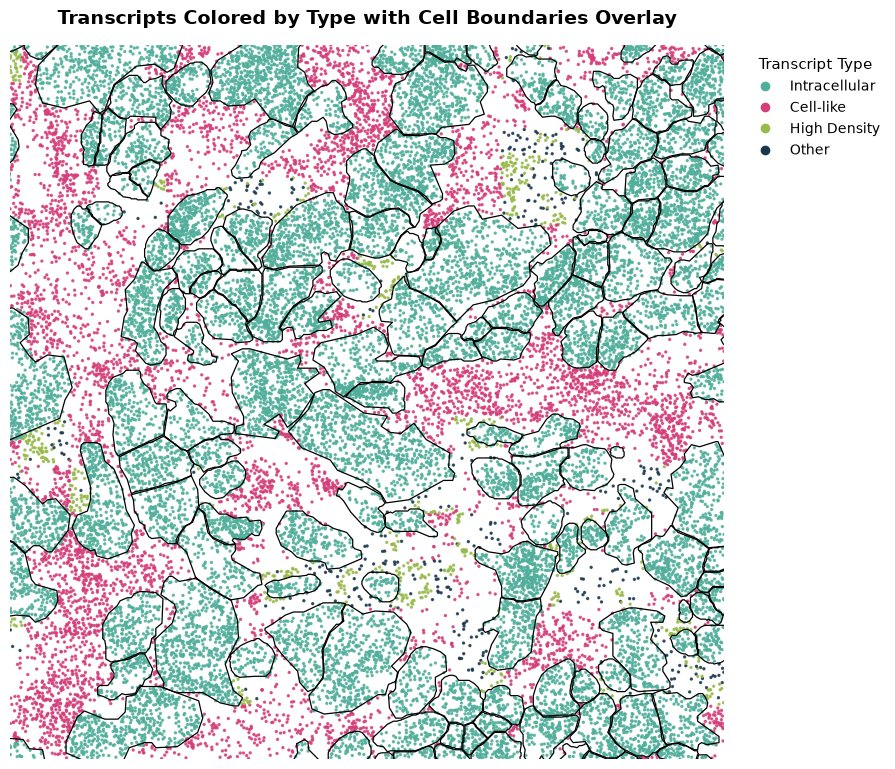

In [26]:
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. Process Transcripts & Cell Boundaries
# -------------------------------------------------------------------------
boundaries = sdata["cell_boundaries"]
if hasattr(boundaries, "compute"):
    boundaries = boundaries.compute()

# Extract and compute transcripts into a Pandas DataFrame FIRST
transcripts = sdata["transcripts"]
if hasattr(transcripts, "compute"):
    transcripts = transcripts.compute()


# Helper function to convert boolean strings safely
def to_bool_series(series):
    if pd.api.types.is_bool_dtype(series):
        return series
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "t", "yes"])


# Convert boolean columns to true boolean Series
overlaps_cell_bool = to_bool_series(transcripts["overlaps_cell"])
extracellular_bool = to_bool_series(transcripts["extracellular"])

# Define conditions in order of priority using Pandas Series
conditions = [
    overlaps_cell_bool,
    ~extracellular_bool,  # extracellular == False
    transcripts["enrichment_class"].astype(str) == "High Density",
]

# Define corresponding labels for each condition
choices = [
    "Intracellular",
    "Cell-like",
    "High Density",
]

# Apply categorical transcript type assignment
transcripts["transcript_type"] = np.select(conditions, choices, default="Other")
transcripts["transcript_type"] = transcripts["transcript_type"].astype(str)

# -------------------------------------------------------------------------
# 2. Shift and Scale Coordinates
# -------------------------------------------------------------------------
# Compute minimums and maximums from transcript coordinates
t_minx = float(transcripts["x"].min())
t_maxx = float(transcripts["x"].max())
t_miny = float(transcripts["y"].min())
t_maxy = float(transcripts["y"].max())

# Calculate scaling factors based on background image dimensions
img_h, img_w = background_image.shape
mfx = img_w / (t_maxx - t_minx)
mfy = img_h / (t_maxy - t_miny)

# Translate & scale cell boundaries
boundaries_shifted = boundaries.copy()
boundaries_shifted["geometry"] = boundaries_shifted.geometry.translate(
    xoff=-t_minx, yoff=-t_miny
)
boundaries_shifted["geometry"] = boundaries_shifted.geometry.scale(
    xfact=mfx, yfact=mfy, origin=(0, 0)
)

# Translate & scale transcript coordinates to match image alignment
transcripts_shifted = transcripts.copy()
transcripts_shifted["x_scaled"] = (transcripts["x"] - t_minx) * mfx
transcripts_shifted["y_scaled"] = (transcripts["y"] - t_miny) * mfy

# -------------------------------------------------------------------------
# 3. Custom Color Mapping & Spatial ROI Filtering
# -------------------------------------------------------------------------
# Define custom palette mapping
type_color_map = {
    "Intracellular": "#51ae9b",
    "Cell-like": "#d53e7a",
    "High Density": "#98b94c",
    "Other": "#1a364d",
}

transcripts_shifted["color"] = transcripts_shifted["transcript_type"].map(
    type_color_map
)

# ROI definition
xmin, xmax = 0, 700
ymin, ymax = 0, 700

# Spatial filter transcripts within ROI bounds
transcripts_roi = transcripts_shifted[
    (transcripts_shifted["x_scaled"] >= xmin)
    & (transcripts_shifted["x_scaled"] <= xmax)
    & (transcripts_shifted["y_scaled"] >= ymin)
    & (transcripts_shifted["y_scaled"] <= ymax)
].copy()

# Spatial filter GeoDataFrame using GeoPandas .cx coordinate indexer
boundaries_roi = boundaries_shifted.cx[xmin:xmax, ymin:ymax].copy()

# -------------------------------------------------------------------------
# 4. Plot Transcripts & Overlay Cell Boundaries in ROI
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: Scatter plot of ROI-filtered transcripts
ax.scatter(
    transcripts_roi["x_scaled"],
    transcripts_roi["y_scaled"],
    c=transcripts_roi["color"],
    s=2,
    alpha=0.8,
    rasterized=True,
)

# Layer 2: Overlay ROI-filtered Boundaries
boundaries_roi.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.9,
    alpha=1.0,
)

# -------------------------------------------------------------------------
# 5. Set ROI Limits & Clean Axis
# -------------------------------------------------------------------------
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymax, ymin)  # Inverted Y-axis to match spatial image coordinates

ax.set_title(
    "Transcripts Colored by Type with Cell Boundaries Overlay",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.axis("off")

# -------------------------------------------------------------------------
# 6. Matching Legend & Export
# -------------------------------------------------------------------------
unique_types_present = [
    t for t in type_color_map.keys() if t in transcripts_roi["transcript_type"].unique()
]

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=ttype,
        markerfacecolor=type_color_map[ttype],
        markersize=8,
    )
    for ttype in unique_types_present
]

ax.legend(
    handles=legend_elements,
    title="Transcript Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=10,
    title_fontsize=11,
)

plt.tight_layout()

if "saving_path" in locals() and saving_path is not None:
    plt.savefig(
        os.path.join(saving_path, "transcripts_by_type_roi_custom_colors.pdf"),
        format="pdf",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()

## Individual channels for the ROI (grayscale, cell boundaries in red)

Same ROI as the SOM community / transcripts plots above. The raw `morphology_focus` image shares the same pixel grid as the SOM label image (`background_image`), so it can be cropped with the same `xmin`/`xmax`/`ymin`/`ymax` and overlaid with the same `boundaries_roi`.

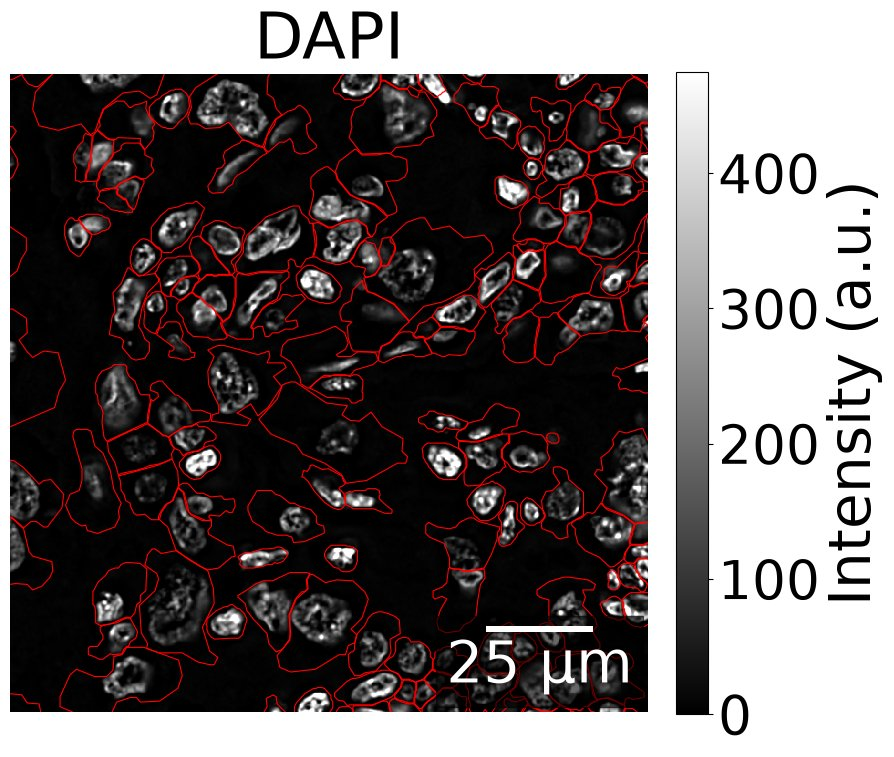

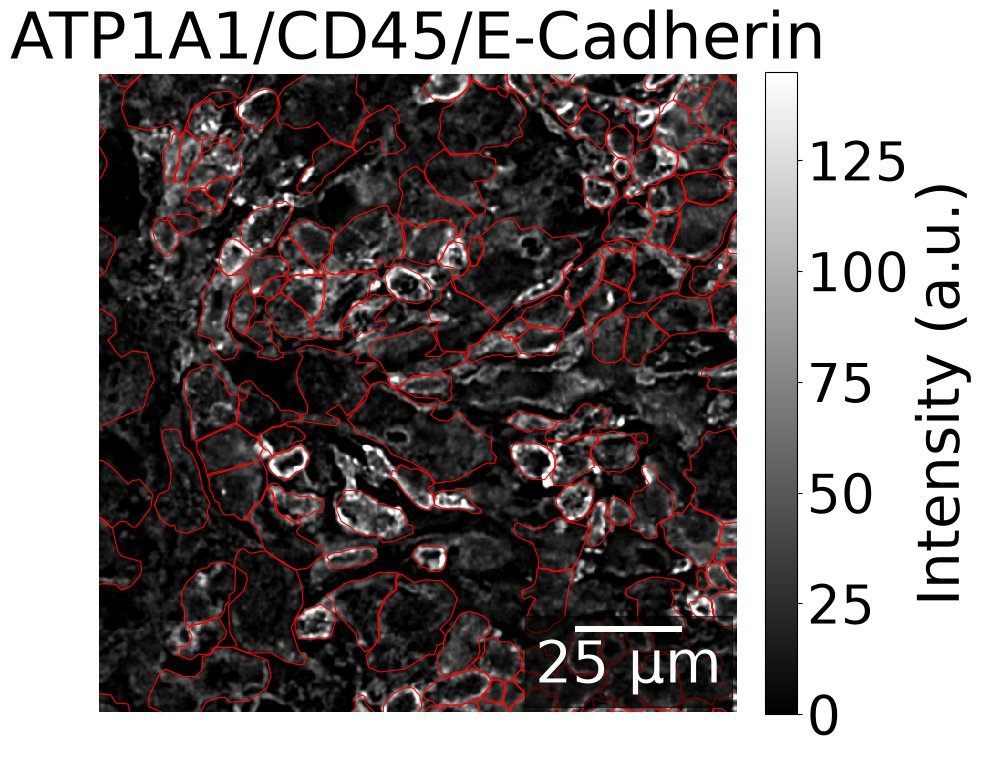

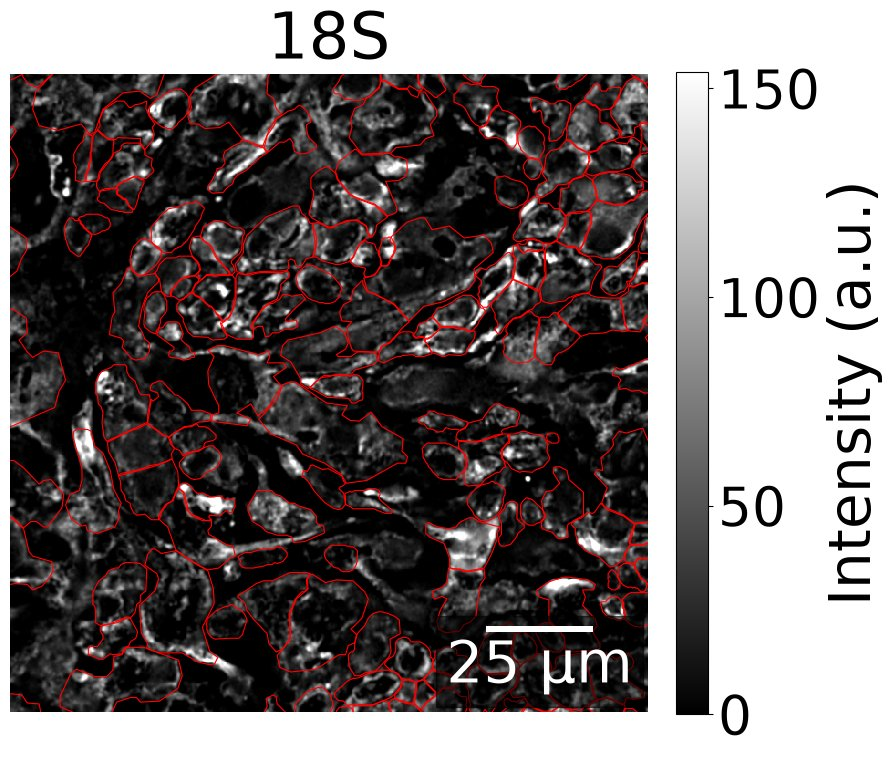

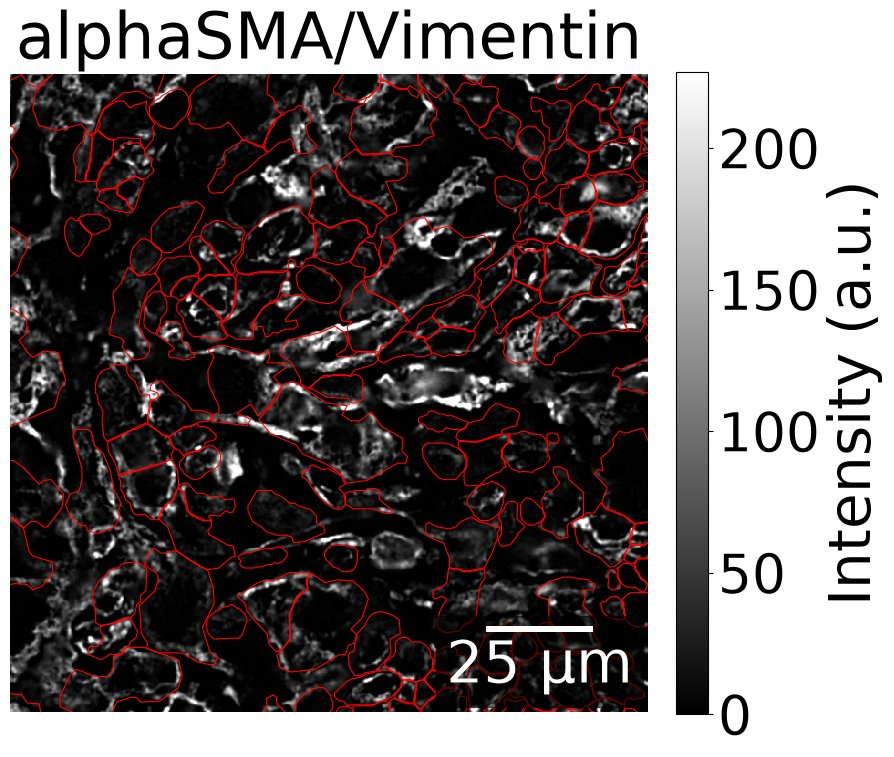

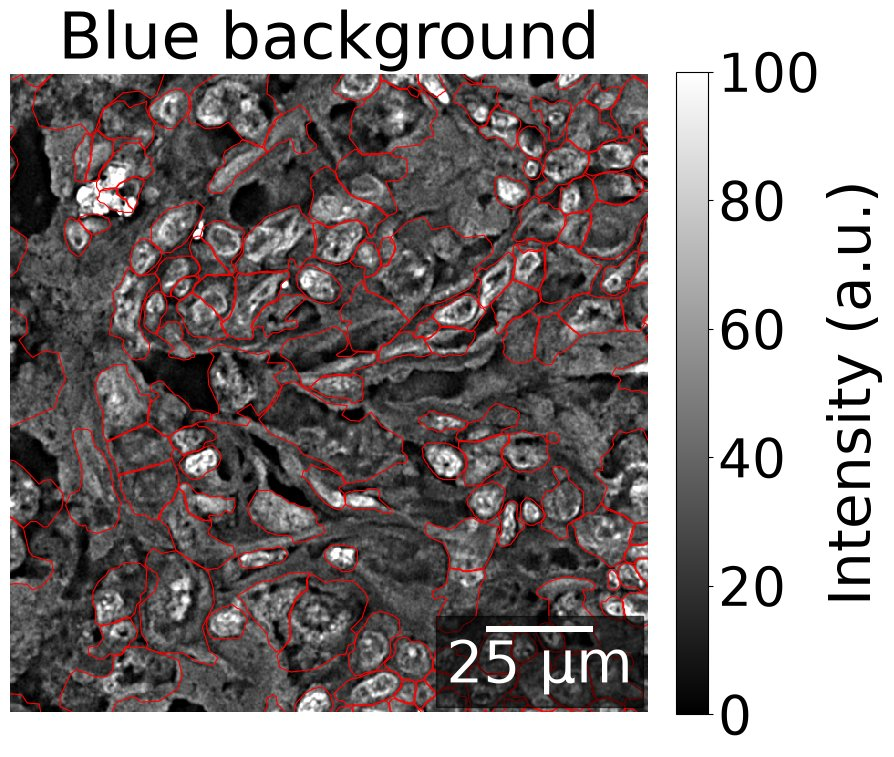

...

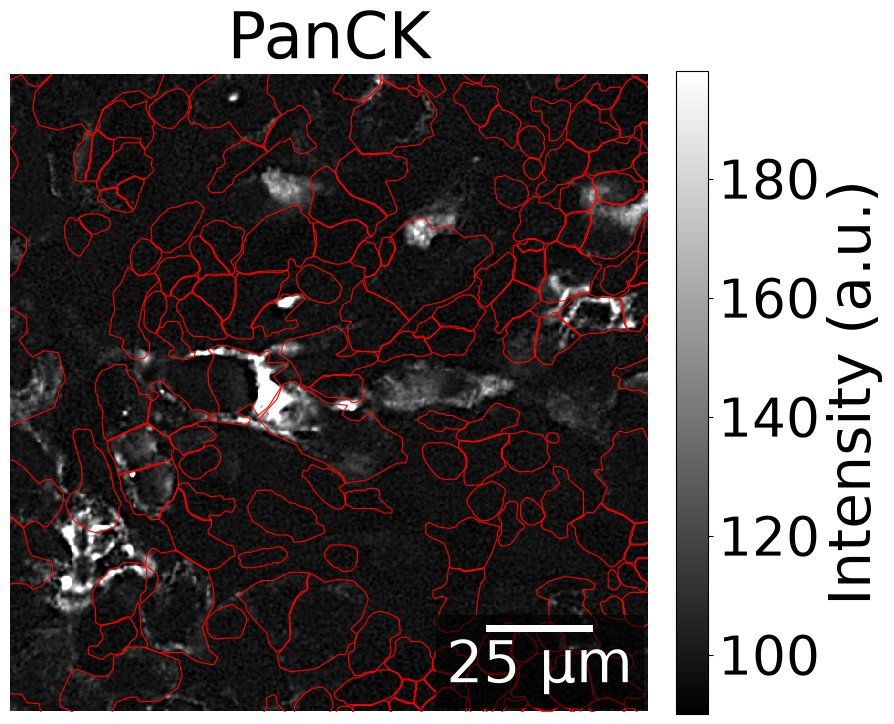

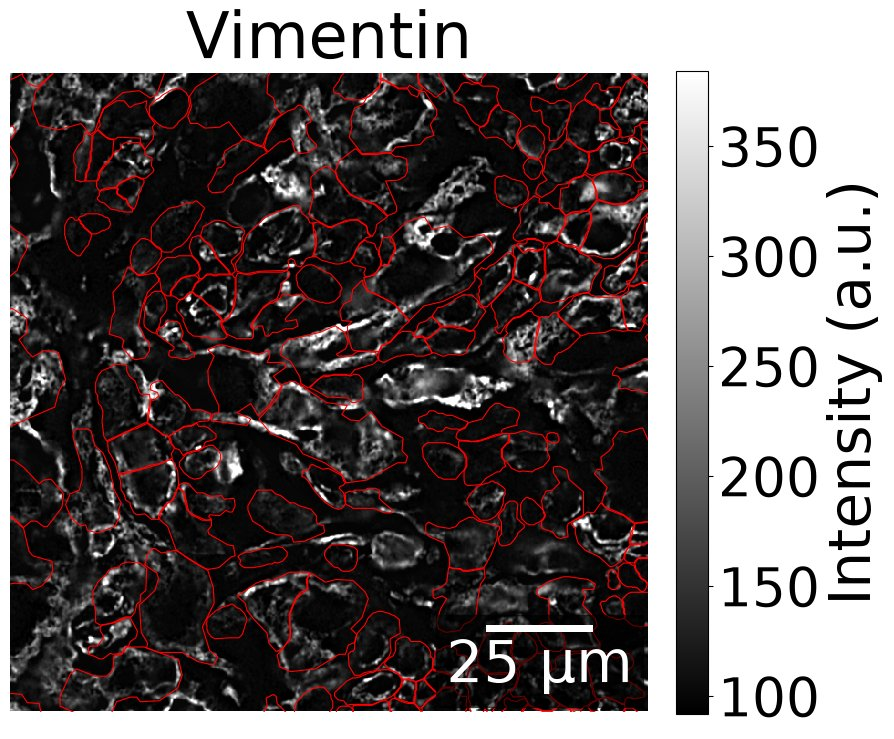

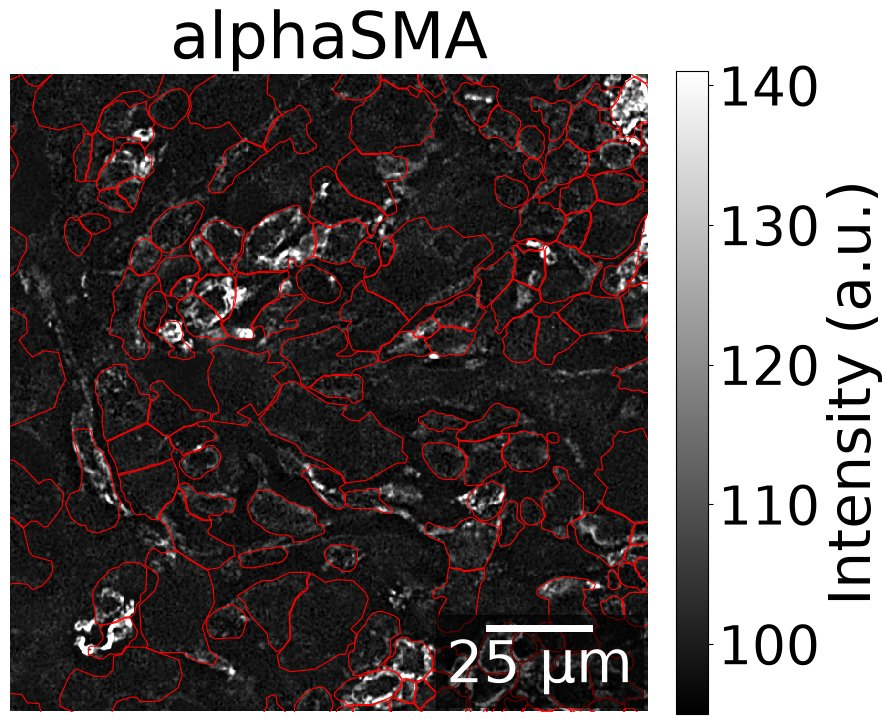

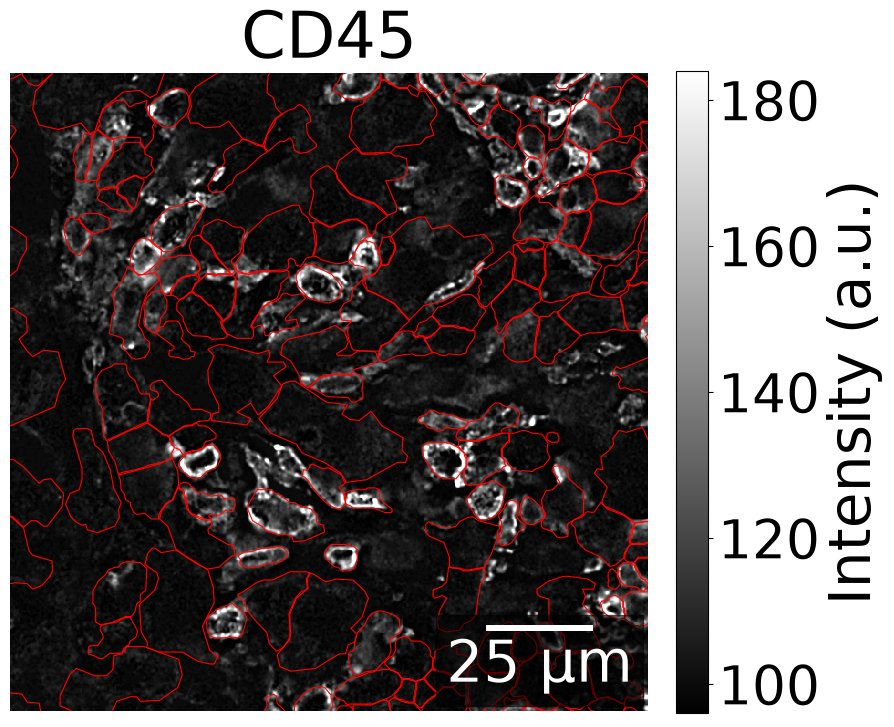

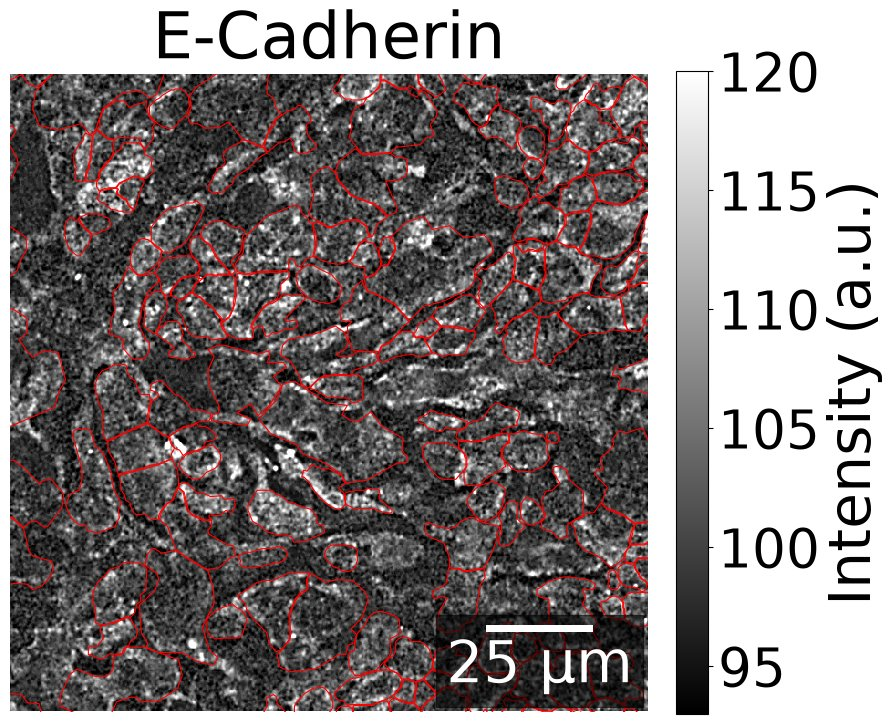

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar

img_s0 = sdata.images["morphology_focus"]["scale0"]["image"]
channel_names = list(img_s0.coords["c"].values)
microns_per_pixel = 1 / mfx

for ch in channel_names:
    crop = img_s0.sel(c=ch).isel(y=slice(ymin, ymax), x=slice(xmin, xmax)).values
    vmin = np.percentile(crop, 1)
    vmax = np.percentile(crop, 99.5)
    if vmax <= vmin:
        vmax = max(crop.max(), vmin + 1)

    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(crop, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
    boundaries_roi.plot(ax=ax, facecolor="none", edgecolor="red", linewidth=0.8)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymax, ymin)
    ax.set_title(ch)
    ax.axis("off")

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Intensity (a.u.)")

    ax.add_artist(
        ScaleBar(
            microns_per_pixel,
            units="um",
            location="lower right",
            color="white",
            box_color="black",
            box_alpha=0.6,
        )
    )

    plt.tight_layout()

    if "saving_path" in locals() and saving_path is not None:
        safe_name = ch.replace("/", "_").replace(" ", "_")
        plt.savefig(
            os.path.join(saving_path, f"channel_{safe_name}_ROI.pdf"),
            format="pdf",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close()

## Per-channel spatial map: channel image + boundaries + most-enriched RNA (colored by RNA type)

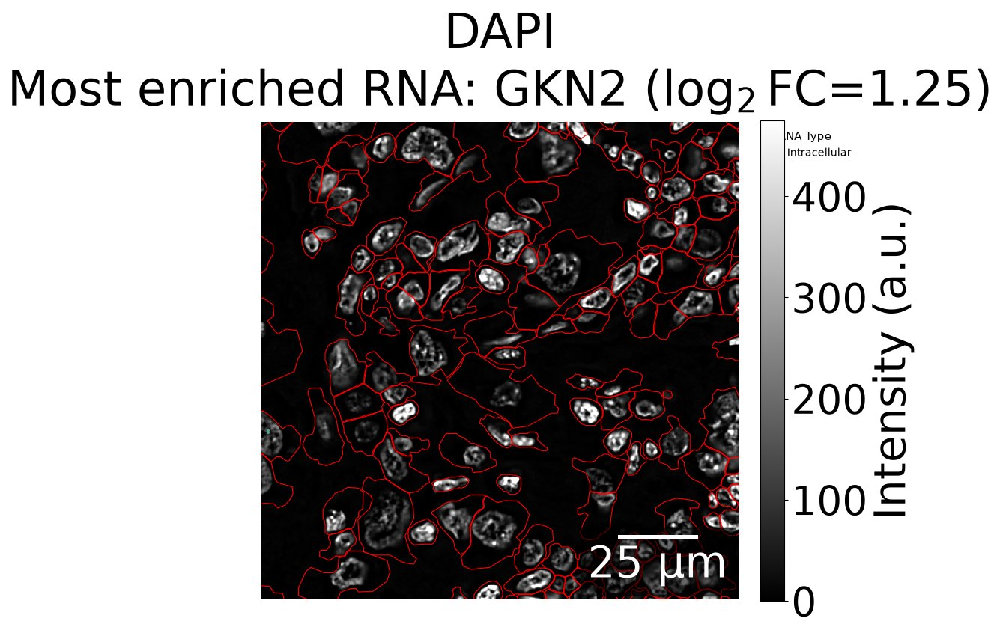

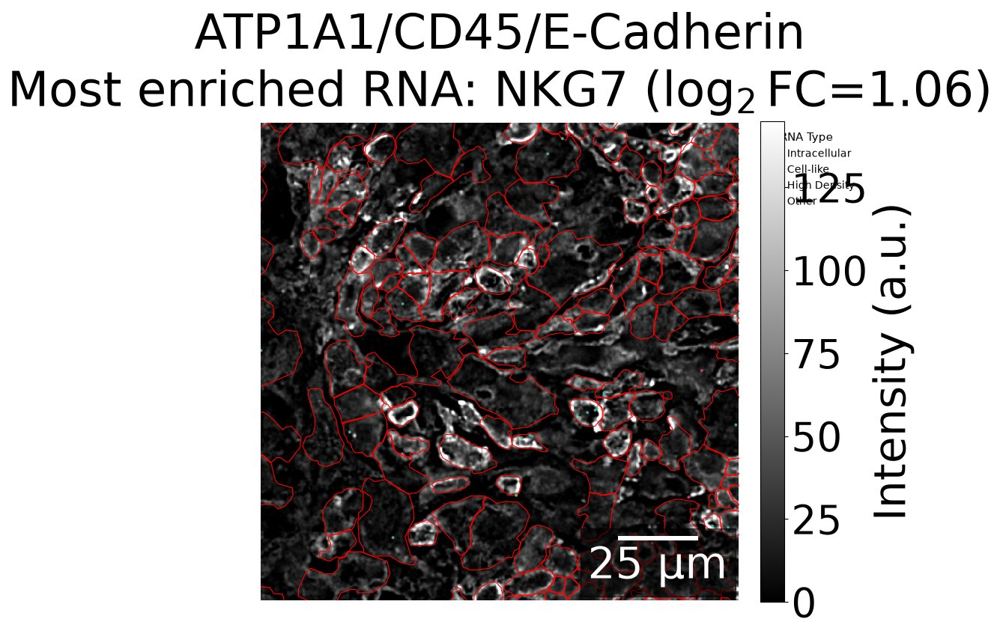

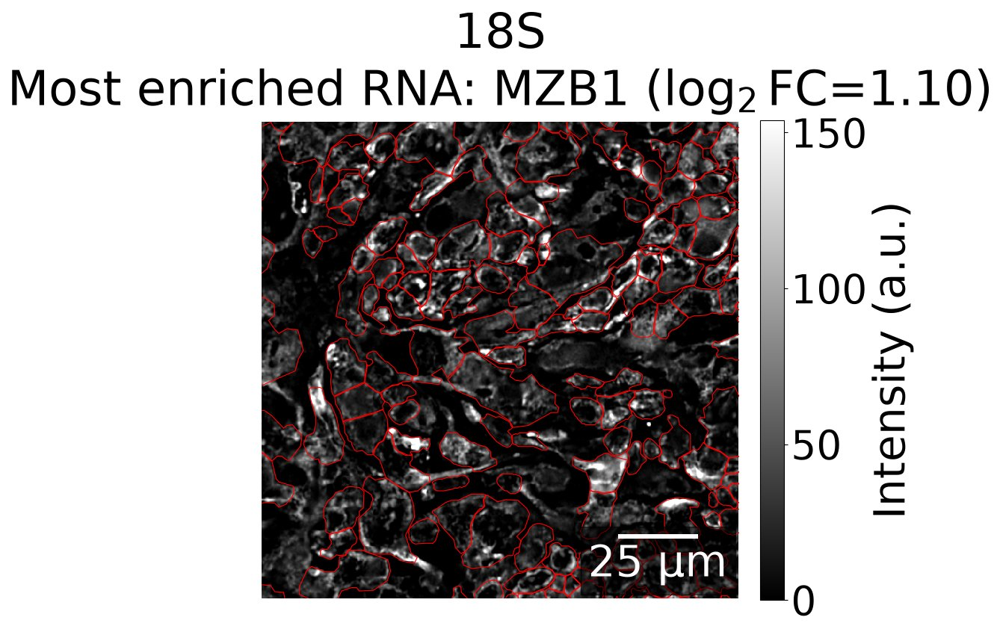

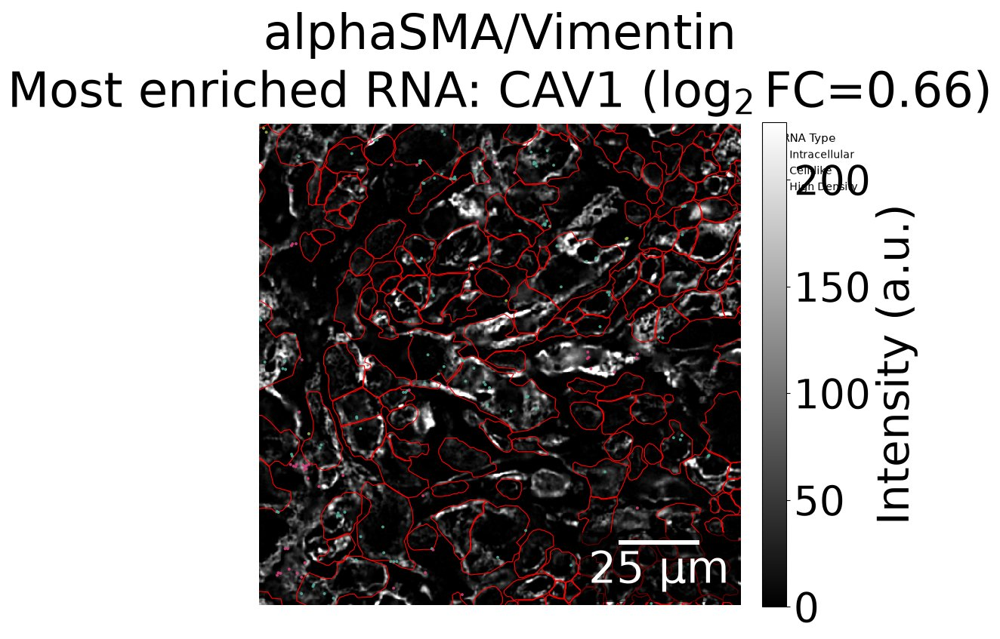

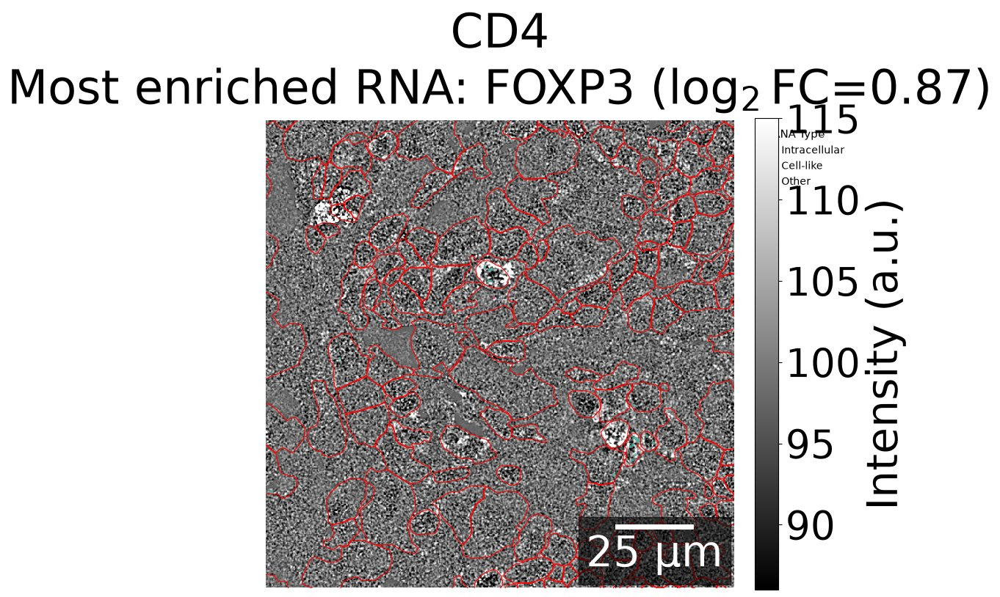

...

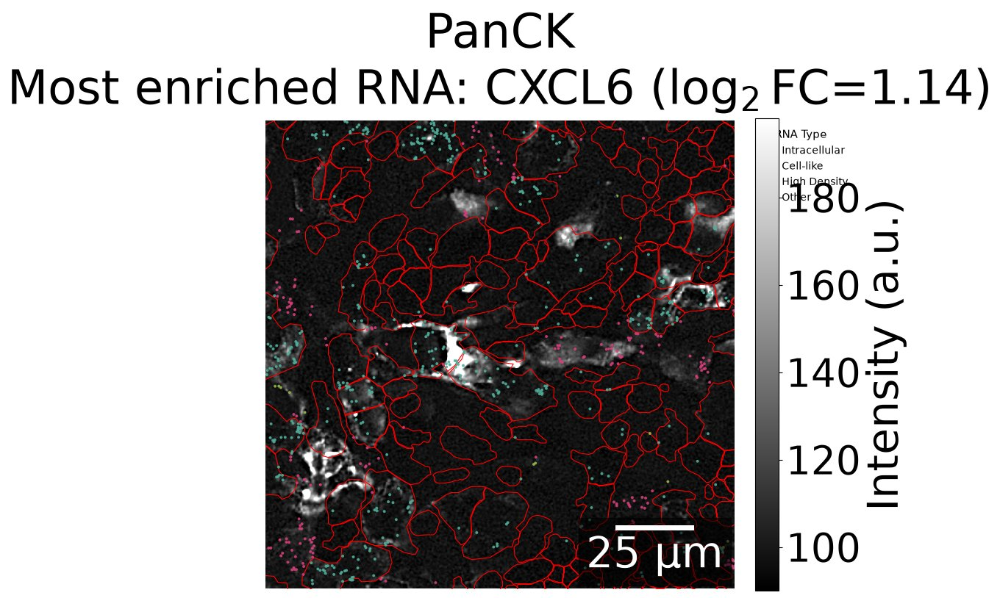

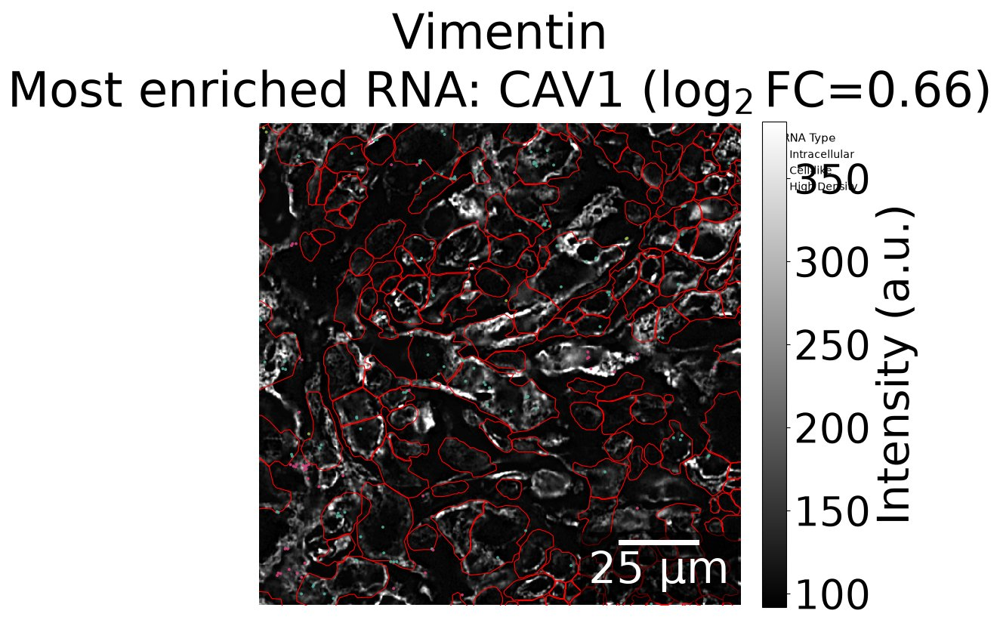

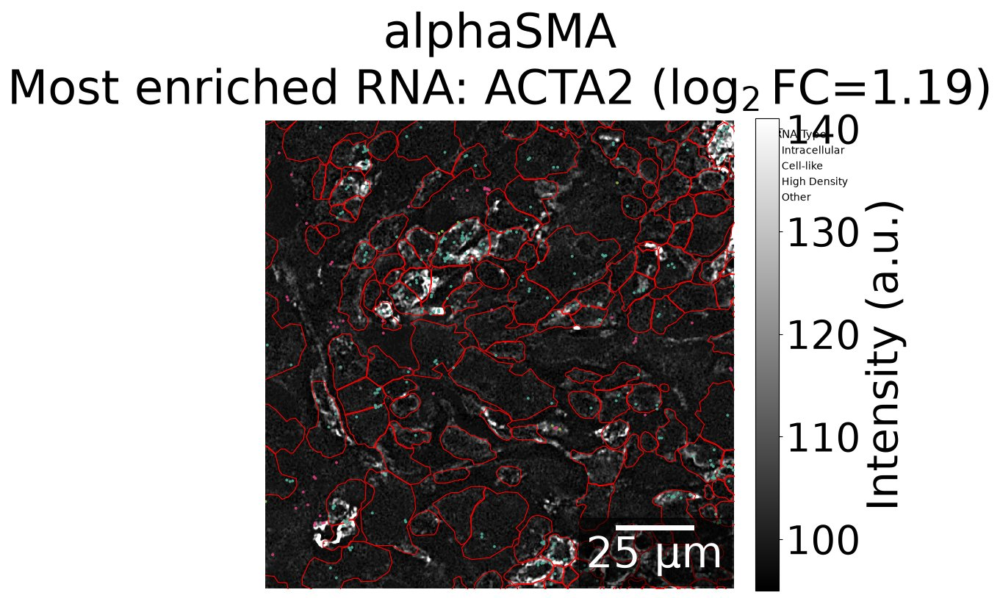

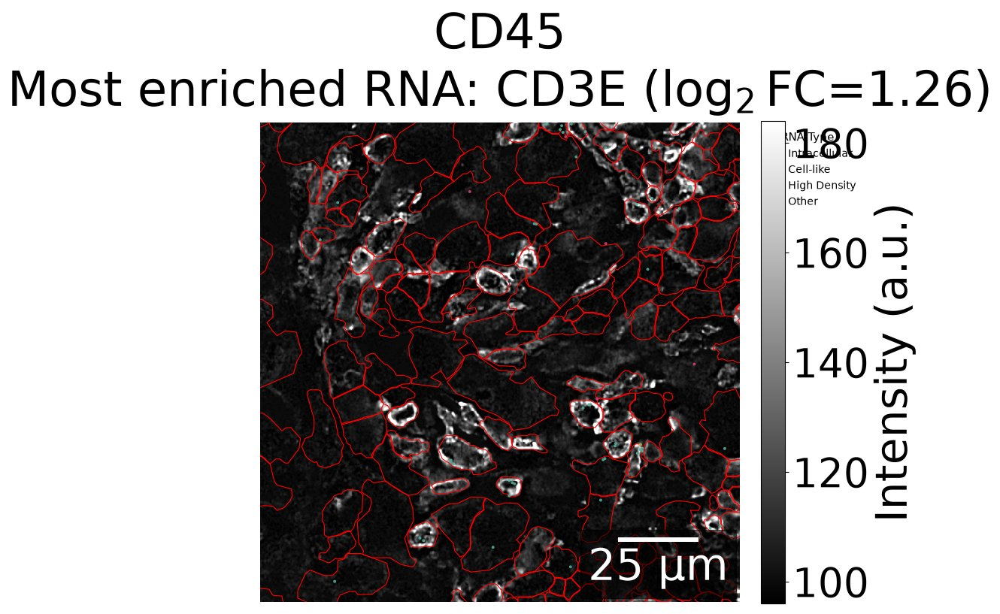

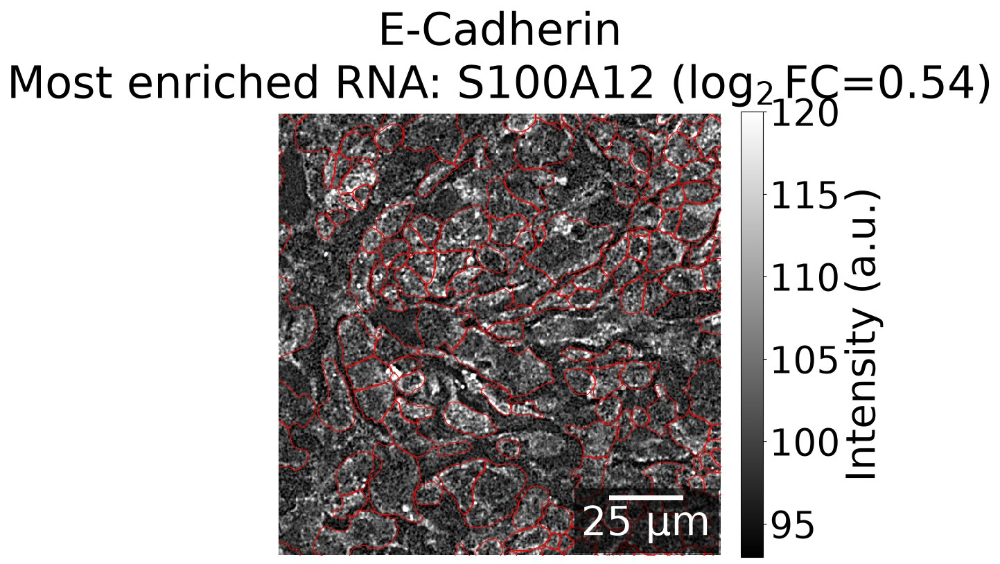

In [28]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib_scalebar.scalebar import ScaleBar

# -------------------------------------------------------------------------
# 1. Per-transcript channel intensities (rows align positionally with `transcripts`)
# -------------------------------------------------------------------------
intensity_adata = sdata.tables["image_intensity_per_transcript"]
if hasattr(intensity_adata.X, "toarray"):
    intensity_df = pd.DataFrame(intensity_adata.X.toarray(), columns=intensity_adata.var_names)
else:
    intensity_df = pd.DataFrame(intensity_adata.X, columns=intensity_adata.var_names)

intensity_df["gene"] = transcripts[gene_key].values
intensity_df["transcript_type"] = transcripts["transcript_type"].values
intensity_df["x_scaled"] = transcripts_shifted["x_scaled"].values
intensity_df["y_scaled"] = transcripts_shifted["y_scaled"].values

# Restrict enrichment to real genes only (exclude control probes / unassigned
# codewords), matching the `control_probe` / `is_gene` QC filtering troutpy
# applies elsewhere in this project (e.g. `troutpy.pp.filter_urna`).
is_real_gene = transcripts["is_gene"].values & ~transcripts["control_probe"].values
intensity_df = intensity_df.loc[is_real_gene].copy()

channel_names_clean = [
    c
    for c in intensity_adata.var_names
    if "background" not in c.lower()
]

overall_gene_freq = intensity_df["gene"].value_counts(normalize=True)

img_s0 = sdata.images["morphology_focus"]["scale0"]["image"]
microns_per_pixel = 1 / mfx

# -------------------------------------------------------------------------
# 2. For each channel: define "positive pixels" as transcripts whose local
#    channel intensity exceeds the channel's 75th percentile, then rank
#    genes by enrichment (frequency among positive pixels vs. overall).
# -------------------------------------------------------------------------
for ch in channel_names_clean:
    thresh = intensity_df[ch].quantile(0.75)
    positive_mask = intensity_df[ch] > thresh
    pos_genes = intensity_df.loc[positive_mask, "gene"]

    if pos_genes.empty:
        continue

    gene_counts = pos_genes.value_counts()
    gene_counts = gene_counts[gene_counts >= 10]  # minimum transcript support
    if gene_counts.empty:
        continue

    pos_freq = gene_counts / gene_counts.sum()
    enrichment = (pos_freq / overall_gene_freq.reindex(pos_freq.index)).sort_values(
        ascending=False
    )
    top_gene = enrichment.index[0]
    top_logfc = np.log2(enrichment.iloc[0])

    # ROI crop of the channel's own grayscale image
    crop = img_s0.sel(c=ch).isel(y=slice(ymin, ymax), x=slice(xmin, xmax)).values
    vmin = np.percentile(crop, 1)
    vmax = np.percentile(crop, 99.5)
    if vmax <= vmin:
        vmax = max(crop.max(), vmin + 1)

    # Transcripts of the top enriched gene, restricted to the display ROI
    gene_roi = transcripts_shifted[
        (transcripts_shifted[gene_key] == top_gene)
        & (transcripts_shifted["x_scaled"] >= xmin)
        & (transcripts_shifted["x_scaled"] <= xmax)
        & (transcripts_shifted["y_scaled"] >= ymin)
        & (transcripts_shifted["y_scaled"] <= ymax)
    ].copy()
    gene_roi["color"] = gene_roi["transcript_type"].map(type_color_map)

    fig, ax = plt.subplots(figsize=(10, 10))

    # Layer 1: channel grayscale background
    im = ax.imshow(crop, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")

    # Layer 2: cell boundaries
    boundaries_roi.plot(ax=ax, facecolor="none", edgecolor="red", linewidth=0.8)

    # Layer 3: most-enriched-gene transcripts, colored by RNA type
    ax.scatter(
        gene_roi["x_scaled"],
        gene_roi["y_scaled"],
        c=gene_roi["color"],
        s=8,
        alpha=0.9,
        linewidths=0,
        rasterized=True,
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymax, ymin)
    ax.set_title(f"{ch}\nMost enriched RNA: {top_gene} ($\log_2$FC={top_logfc:.2f})")
    ax.axis("off")

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Intensity (a.u.)")

    ax.add_artist(
        ScaleBar(
            microns_per_pixel,
            units="um",
            location="lower right",
            color="white",
            box_color="black",
            box_alpha=0.6,
        )
    )

    unique_types_present = [
        t for t in type_color_map if t in gene_roi["transcript_type"].unique()
    ]
    if unique_types_present:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                label=t,
                markerfacecolor=type_color_map[t],
                markersize=8,
            )
            for t in unique_types_present
        ]
        ax.legend(
            handles=legend_elements,
            title="RNA Type",
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            frameon=False,
            fontsize=10,
            title_fontsize=11,
        )

    plt.tight_layout()

    if "saving_path" in locals() and saving_path is not None:
        safe_ch = ch.replace("/", "_").replace(" ", "_")
        safe_gene = str(top_gene).replace("/", "_").replace(" ", "_")
        plt.savefig(
            os.path.join(
                saving_path, f"channel_{safe_ch}_top_gene_{safe_gene}_ROI.pdf"
            ),
            format="pdf",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close()


## Define transcript types within transcripts

In [29]:
# Extract and compute transcripts into a Pandas DataFrame FIRST
transcripts = sdata["transcripts"]
if hasattr(transcripts, "compute"):
    transcripts = transcripts.compute()

# Helper function to convert boolean strings safely
def to_bool_series(series):
    if pd.api.types.is_bool_dtype(series):
        return series
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "t", "yes"])


# Convert boolean columns to true boolean Series
overlaps_cell_bool = to_bool_series(transcripts["overlaps_cell"])
extracellular_bool = to_bool_series(transcripts["extracellular"])

# Define conditions in order of priority using Pandas Series
conditions = [
    overlaps_cell_bool,
    ~extracellular_bool,  # extracellular == False
    transcripts["enrichment_class"].astype(str) == "High Density",
]

# Define corresponding labels for each condition
choices = [
    "Intracellular",
    "Cell-like",
    "High Density",
]

# Apply categorical transcript type assignment
transcripts["transcript_type"] = np.select(conditions, choices, default="Other")
transcripts["transcript_type"] = transcripts["transcript_type"].astype(str)

#

In [30]:
transcripts['som_label']=transcripts['som_community'].astype(str)+'_'+transcripts['som_community'].map(lambda x: som_labels.get(x, f"Community {x}"))

Given `transcripts`, with `transcript_type`, `som_label` (the SOM cluster) and `gene`, compute the enrichment of each gene in each SOM cluster. The core question: is there a different enrichment of genes in a SOM cluster depending on the transcript type we are working with?

In [31]:
# Didfferences across transcript type

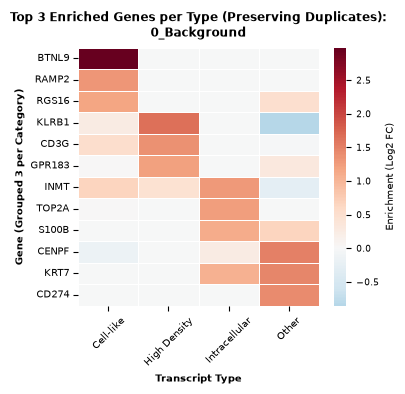

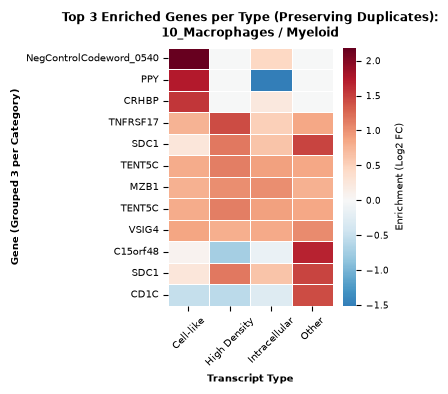

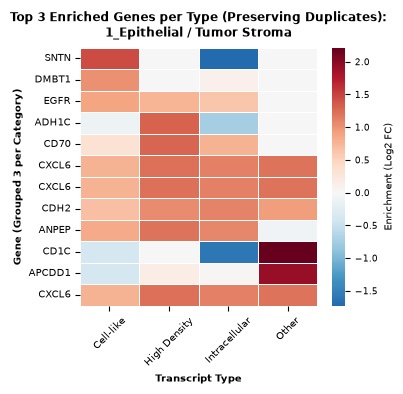

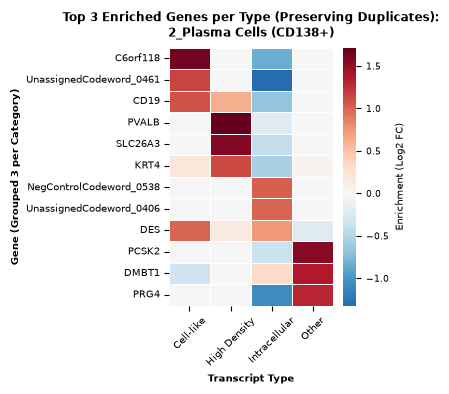

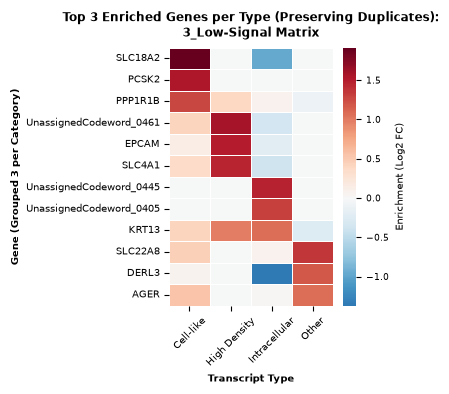

...

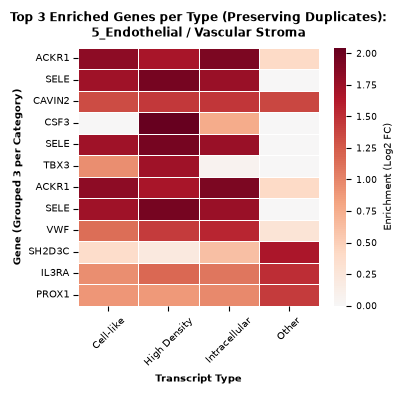

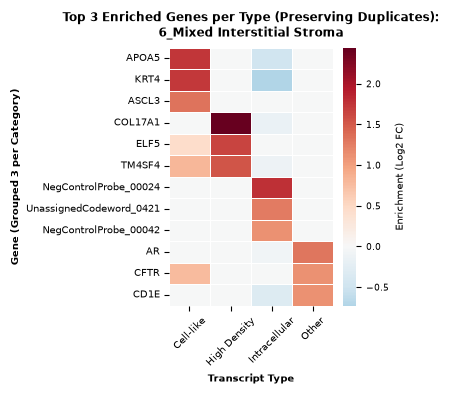

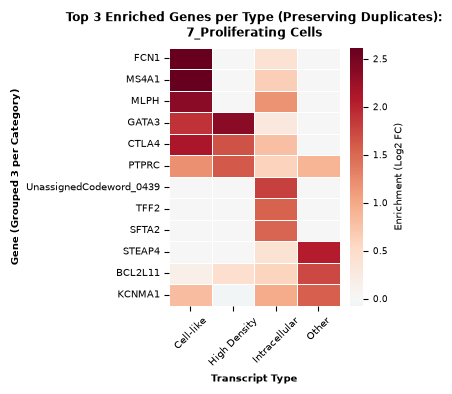

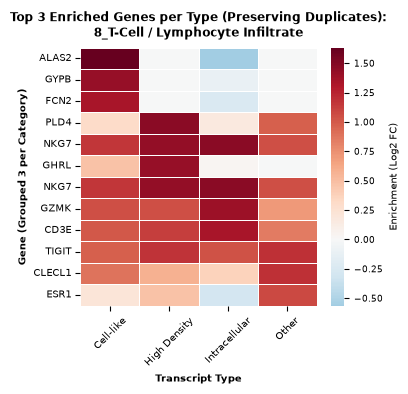

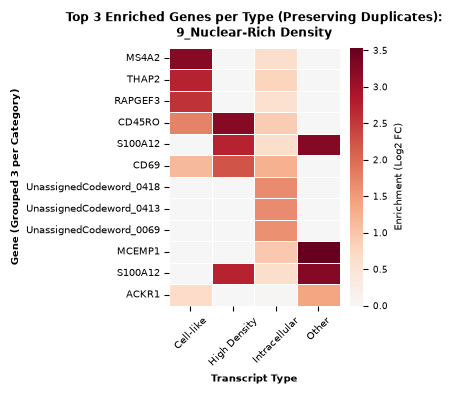

In [32]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests


# -------------------------------------------------------------------------
# 1. Stratified Gene Enrichment Loop (Within each transcript_type)
# -------------------------------------------------------------------------
def run_stratified_enrichment(df, min_count=5):
    results = []

    # Filter out missing records
    valid_df = df.dropna(subset=["gene", "som_label", "transcript_type"]).copy()

    # Iterate over each independent transcript_type universe
    for ttype, type_df in valid_df.groupby("transcript_type"):
        total_type_transcripts = len(type_df)
        gene_type_counts = type_df["gene"].value_counts()

        for som_label, cluster_df in type_df.groupby("som_label"):
            cluster_size = len(cluster_df)
            gene_cluster_counts = cluster_df["gene"].value_counts()

            for gene, observed in gene_cluster_counts.items():
                if observed < min_count:
                    continue

                total_gene = gene_type_counts[gene]

                # Expected under uniform spatial distribution of Type A
                expected = (total_gene * cluster_size) / total_type_transcripts
                oe_ratio = observed / expected if expected > 0 else 0
                log2_fc = np.log2(oe_ratio) if oe_ratio > 0 else 0.0

                # Fisher's Exact Test within Type A
                a = observed
                b = total_gene - observed
                c = cluster_size - observed
                d = total_type_transcripts - a - b - c

                odds_ratio, pval = fisher_exact([[a, b], [c, d]])

                results.append(
                    {
                        "transcript_type": ttype,
                        "som_label": som_label,
                        "gene": gene,
                        "observed": observed,
                        "expected": expected,
                        "log2_fc": log2_fc,
                        "p_value": pval,
                    }
                )

    res_df = pd.DataFrame(results)

    # BH-FDR correction within each transcript type group
    res_df["fdr"] = 1.0
    for ttype in res_df["transcript_type"].unique():
        mask = res_df["transcript_type"] == ttype
        if mask.any():
            _, fdr_vals, _, _ = multipletests(
                res_df.loc[mask, "p_value"], method="fdr_bh"
            )
            res_df.loc[mask, "fdr"] = fdr_vals

    return res_df


# Run the computation
enrichment_results = run_stratified_enrichment(transcripts)

# -------------------------------------------------------------------------
# 2. Heatmaps: Exactly 3 Top Genes per Category (Including Repeats)
# -------------------------------------------------------------------------
valid_clusters = sorted(
    [
        c
        for c in enrichment_results["som_label"].unique()
        if str(c).lower() not in ["background", "nan", "none", "0"]
    ]
)

for cluster_name in valid_clusters:
    cluster_data = enrichment_results[
        enrichment_results["som_label"] == cluster_name
    ]
    if cluster_data.empty:
        continue

    sorted_ttypes = sorted(cluster_data["transcript_type"].unique())

    # Build matrix maintaining duplicates per category
    ordered_rows = []
    display_gene_labels = []

    for ttype in sorted_ttypes:
        ttype_sub = cluster_data[cluster_data["transcript_type"] == ttype]
        top_3_genes = ttype_sub.nlargest(3, "log2_fc")["gene"].tolist()

        # Pad with placeholders if a category has fewer than 3 enriched genes
        while len(top_3_genes) < 3:
            top_3_genes.append("N/A")

        for idx, gene_name in enumerate(top_3_genes):
            # Create a unique key for DataFrame row indexing (appends invisible spaces for duplicates)
            unique_row_key = f"{gene_name}___{ttype}_{idx}"
            display_gene_labels.append(gene_name)

            row_values = {}
            for col_ttype in sorted_ttypes:
                val = cluster_data[
                    (cluster_data["gene"] == gene_name)
                    & (cluster_data["transcript_type"] == col_ttype)
                ]["log2_fc"].values

                row_values[col_ttype] = val[0] if len(val) > 0 else 0.0

            row_values["row_key"] = unique_row_key
            ordered_rows.append(row_values)

    heatmap_df = pd.DataFrame(ordered_rows).set_index("row_key")

    # -------------------------------------------------------------------------
    # 3. Plotting: Display All Rows with Duplicate Gene Names
    # -------------------------------------------------------------------------
    num_rows = len(heatmap_df)
    fig_height = max(5.0, num_rows * 0.3)

    fig, ax = plt.subplots(figsize=(5.0, fig_height))

    sns.heatmap(
        heatmap_df,
        cmap="RdBu_r",
        center=0,
        annot=False,
        yticklabels=display_gene_labels,  # Force clean gene names (including repeats)
        cbar_kws={"label": "Enrichment (Log2 FC)"},
        linewidths=0.5,
        linecolor="white",
        ax=ax,
    )

    ax.set_title(
        f"Top 3 Enriched Genes per Type (Preserving Duplicates):\n{cluster_name}",
        fontsize=8.5,
        fontweight="bold",
        pad=8,
    )
    ax.set_xlabel("Transcript Type", fontsize=7.5, fontweight="bold")
    ax.set_ylabel(
        "Gene (Grouped 3 per Category)", fontsize=7.5, fontweight="bold"
    )

    # Formatting tick labels
    ax.tick_params(axis="x", labelsize=7, rotation=45)
    ax.tick_params(axis="y", labelsize=7, rotation=0, pad=3)

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=6.5)
    cbar.set_label("Enrichment (Log2 FC)", fontsize=7)

    plt.tight_layout()

    # Save outputs
    if "saving_path" in locals() and saving_path is not None:
        safe_name = (
            str(cluster_name)
            .replace(" ", "_")
            .replace("/", "_")
            .replace("+", "plus")
        )
        plt.savefig(
            os.path.join(saving_path, f"top3_strict_enrichment_{safe_name}.pdf"),
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close()

Generating heatmaps for 4 transcript types...


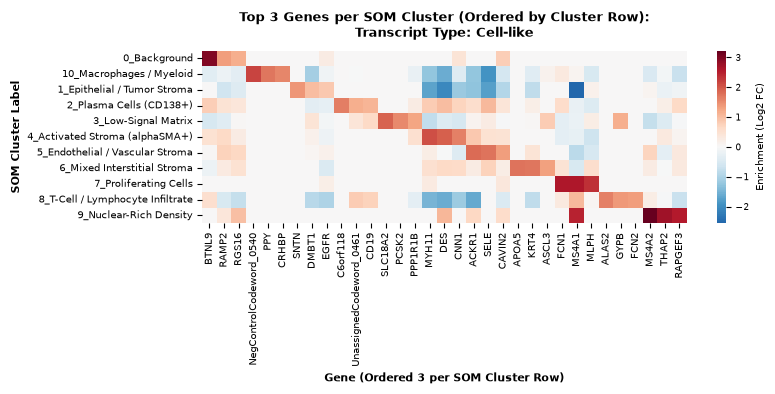

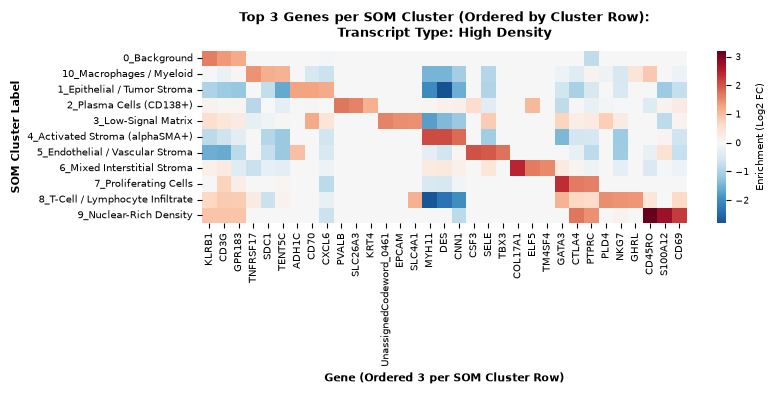

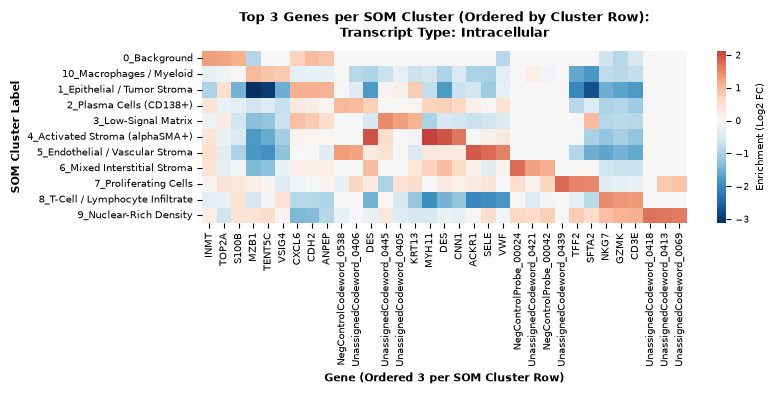

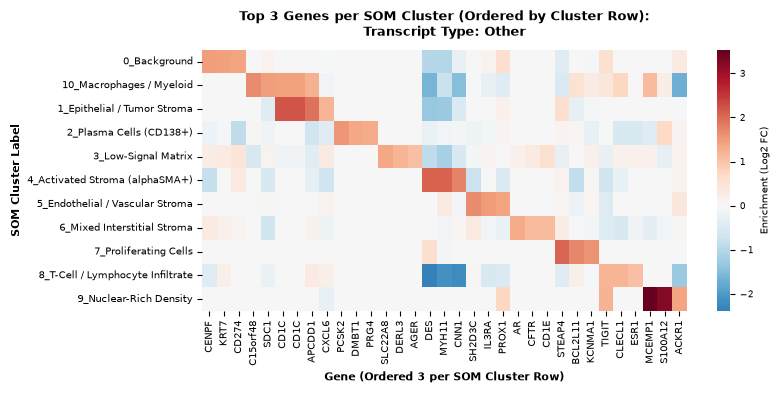

In [33]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# -------------------------------------------------------------------------
# Filter Valid Results (Exclude Background/NaN clusters if present)
# -------------------------------------------------------------------------
valid_results = enrichment_results[
    ~enrichment_results["som_label"]
    .astype(str)
    .str.lower()
    .isin(["background", "nan", "none", "0"])
].copy()

unique_ttypes = sorted(valid_results["transcript_type"].dropna().unique())

print(f"Generating heatmaps for {len(unique_ttypes)} transcript types...")

# -------------------------------------------------------------------------
# Plot 1 Heatmap per Transcript Type (Y: SOM Labels, X: Genes in Row Order)
# -------------------------------------------------------------------------
for ttype in unique_ttypes:
    type_data = valid_results[valid_results["transcript_type"] == ttype].copy()

    if type_data.empty:
        continue

    # Sort SOM clusters deterministically for row ordering
    sorted_som_labels = sorted(type_data["som_label"].unique())

    ordered_columns = []
    display_gene_labels = []

    # Select top 3 genes per SOM cluster and build ordered column sequence
    for som_idx, som_label in enumerate(sorted_som_labels):
        som_sub = type_data[type_data["som_label"] == som_label]
        top_3_genes = som_sub.nlargest(3, "log2_fc")["gene"].tolist()

        # Pad if fewer than 3 enriched genes exist for this cluster
        while len(top_3_genes) < 3:
            top_3_genes.append("N/A")

        for gene_idx, gene_name in enumerate(top_3_genes):
            # Unique key for DataFrame columns (preserves duplicates across X-axis)
            unique_col_key = f"{gene_name}___{som_label}_{gene_idx}"
            display_gene_labels.append(gene_name)

            col_values = {}
            for row_som in sorted_som_labels:
                val = type_data[
                    (type_data["som_label"] == row_som)
                    & (type_data["gene"] == gene_name)
                ]["log2_fc"].values

                col_values[row_som] = val[0] if len(val) > 0 else 0.0

            col_values["col_key"] = unique_col_key
            ordered_columns.append(col_values)

    # Convert to DataFrame (Y = som_label, X = unique_col_key)
    heatmap_df = pd.DataFrame(ordered_columns).set_index("col_key").T

    # Explicitly force row ordering by sorted SOM labels
    heatmap_df = heatmap_df.reindex(sorted_som_labels).fillna(0)

    # -------------------------------------------------------------------------
    # Dynamic Figure Sizing based on number of columns (X) & rows (Y)
    # -------------------------------------------------------------------------
    num_cols = len(heatmap_df.columns)
    num_rows = len(heatmap_df.index)

    fig_width = max(6.0, num_cols * 0.28)
    fig_height = max(5.0, num_rows * 0.35)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    sns.heatmap(
        heatmap_df,
        cmap="RdBu_r",
        center=0,
        annot=False,
        xticklabels=display_gene_labels,  # Shows all gene names including repeats
        yticklabels=True,  # Shows all SOM cluster labels
        cbar_kws={"label": "Enrichment (Log2 FC)"},
        linewidths=0,
        linecolor="white",
        ax=ax,
    )

    ax.set_title(
        f"Top 3 Genes per SOM Cluster (Ordered by Cluster Row):\nTranscript Type: {ttype}",
        fontsize=9,
        fontweight="bold",
        pad=10,
    )
    ax.set_xlabel("Gene (Ordered 3 per SOM Cluster Row)", fontsize=8, fontweight="bold")
    ax.set_ylabel("SOM Cluster Label", fontsize=8, fontweight="bold")

    # Rotate gene labels vertically for neat alignment
    ax.tick_params(axis="x", labelsize=7, rotation=90)
    ax.tick_params(axis="y", labelsize=7, rotation=0, pad=3)

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=6.5)
    cbar.set_label("Enrichment (Log2 FC)", fontsize=7)

    plt.tight_layout()

    # Save outputs
    if "saving_path" in locals() and saving_path is not None:
        safe_ttype = (
            str(ttype)
            .replace(" ", "_")
            .replace("/", "_")
            .replace("+", "plus")
        )
        file_path = os.path.join(
            saving_path, f"top3_by_som_heatmap_{safe_ttype}.pdf"
        )
        plt.savefig(file_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()

In [34]:
import seaborn as sns


# 1. Pivot enrichment (Log2 FC) to compare transcript types side-by-side
enrichment_pivot = enrichment_results.pivot(
    index=["som_label", "gene"], columns="transcript_type", values="log2_fc"
)

# 2. Compute max difference in Log2 FC across transcript types for each (cluster, gene) pair
enrichment_pivot["max_log2fc_diff"] = enrichment_pivot.max(
    axis=1
) - enrichment_pivot.min(axis=1)

# Sort by biggest differences across transcript types
divergent_genes = enrichment_pivot.sort_values(
    by="max_log2fc_diff", ascending=False
)

print("Top Genes/Clusters with divergent enrichment across transcript_types:")
print(divergent_genes.head(15))

Top Genes/Clusters with divergent enrichment across transcript_types:
transcript_type                           Cell-like  High Density  \
som_label                        gene                               
1_Epithelial / Tumor Stroma      CD1C     -0.380203           NaN   
10_Macrophages / Myeloid         PPY       1.730808           NaN   
1_Epithelial / Tumor Stroma      TENT5C   -1.545185     -1.633048   
                                 SNTN      1.435057           NaN   
                                 DNAAF1    0.676065           NaN   
3_Low-Signal Matrix              SLC18A2   1.912969           NaN   
1_Epithelial / Tumor Stroma      CD28     -1.420320     -0.959369   
9_Nuclear-Rich Density           CD34      1.819891     -0.896778   
1_Epithelial / Tumor Stroma      CD300E   -1.600775     -1.212897   
10_Macrophages / Myeloid         CYP2B6    0.823917           NaN   
9_Nuclear-Rich Density           S100A12        NaN      2.721057   
                                 

Generating heatmaps for 11 SOM clusters...


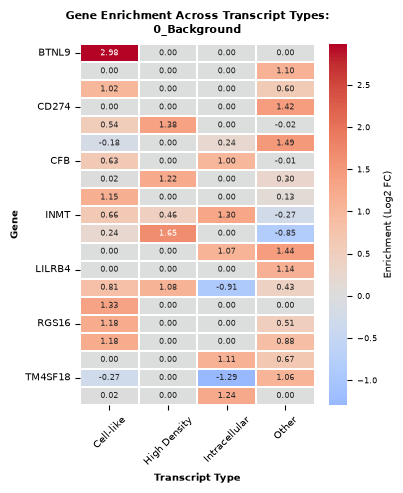

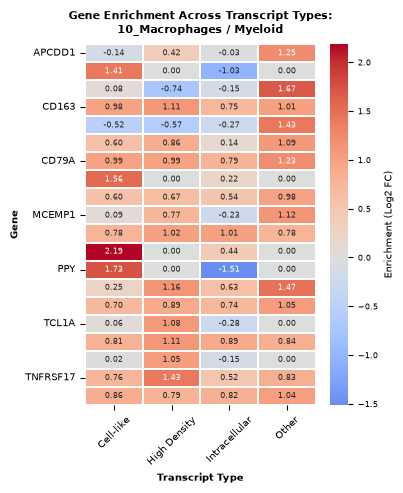

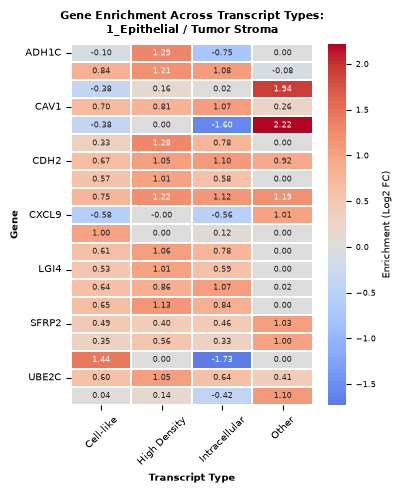

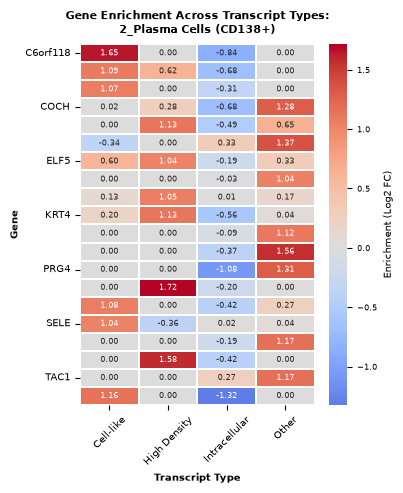

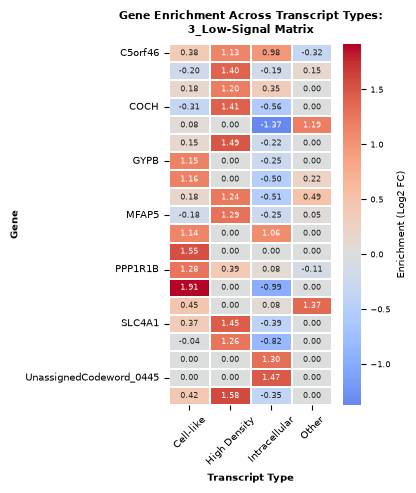

...

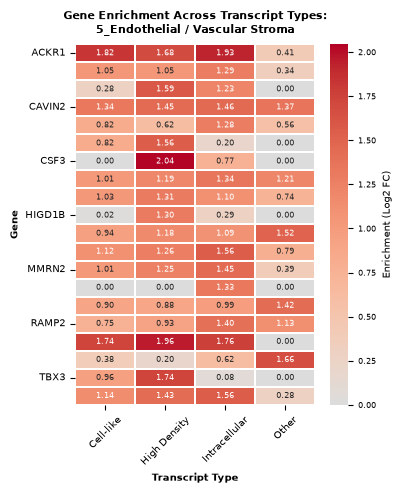

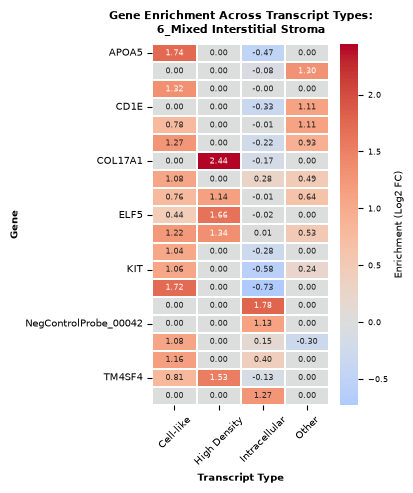

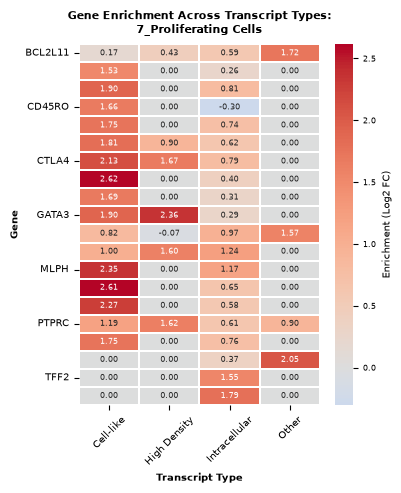

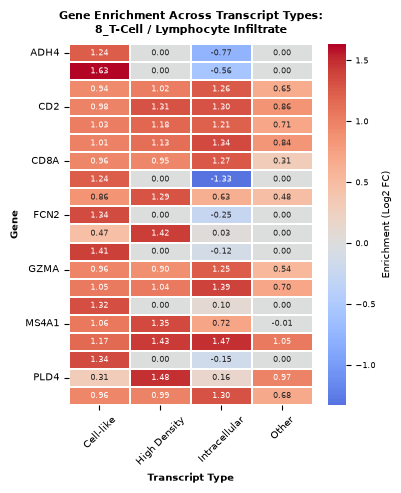

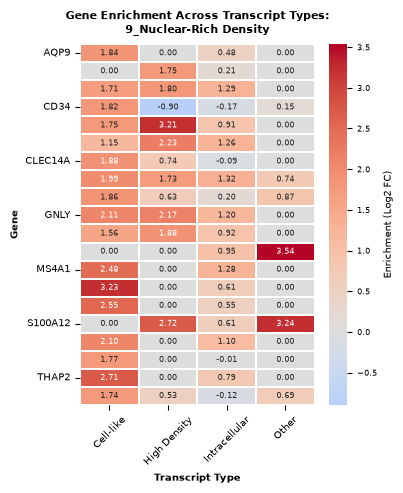

In [35]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------------------------------
# 1. Filter Valid Results & Get Unique Clusters
# -------------------------------------------------------------------------
valid_results = enrichment_results[
    ~enrichment_results["som_label"]
    .astype(str)
    .str.lower()
    .isin(["background", "nan", "none", "0"])
].copy()

# Get all unique SOM clusters to loop over
unique_clusters = sorted(valid_results["som_label"].unique())

print(f"Generating heatmaps for {len(unique_clusters)} SOM clusters...")

# -------------------------------------------------------------------------
# 2. Iterate & Plot Heatmap for EACH SOM Cluster
# -------------------------------------------------------------------------
for cluster_name in unique_clusters:
    cluster_data = valid_results[valid_results["som_label"] == cluster_name]

    if cluster_data.empty:
        continue

    # Get top 20 enriched genes in this specific cluster
    top_genes = (
        cluster_data.groupby("gene")["log2_fc"].max().nlargest(20).index
    )

    # Subset and pivot for heatmap plotting
    heatmap_df = cluster_data[cluster_data["gene"].isin(top_genes)].pivot(
        index="gene", columns="transcript_type", values="log2_fc"
    )

    # Fill NaNs with 0 (un-enriched / undetected)
    heatmap_df = heatmap_df.fillna(0)

    if heatmap_df.empty:
        continue

    # -------------------------------------------------------------------------
    # 3. Plot Heatmap with Compact, Clean Font Sizes
    # -------------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(5, 6))

    sns.heatmap(
        heatmap_df,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 6},  # Small numbers inside cells
        cbar_kws={"label": "Enrichment (Log2 FC)"},
        linewidths=0.3,
        linecolor="white",
        ax=ax,
    )

    # Clean & compact typography
    ax.set_title(
        f"Gene Enrichment Across Transcript Types:\n{cluster_name}",
        fontsize=8,
        fontweight="bold",
        pad=8,
    )
    ax.set_xlabel("Transcript Type", fontsize=7, fontweight="bold")
    ax.set_ylabel("Gene", fontsize=7, fontweight="bold")

    # Tick label formatting
    ax.tick_params(axis="x", labelsize=7, rotation=45)
    ax.tick_params(axis="y", labelsize=7, rotation=0)

    # Adjust colorbar font sizes
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=6)
    cbar.set_label("Enrichment (Log2 FC)", fontsize=7)

    plt.tight_layout()

    # -------------------------------------------------------------------------
    # 4. Save Each Cluster Plot Individually
    # -------------------------------------------------------------------------
    if "saving_path" in locals() and saving_path is not None:
        # Sanitize filename string
        safe_name = (
            str(cluster_name)
            .replace(" ", "_")
            .replace("/", "_")
            .replace("+", "plus")
        )
        file_path = os.path.join(
            saving_path, f"enrichment_{safe_name}.pdf"
        )
        plt.savefig(file_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()

In [36]:
sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)

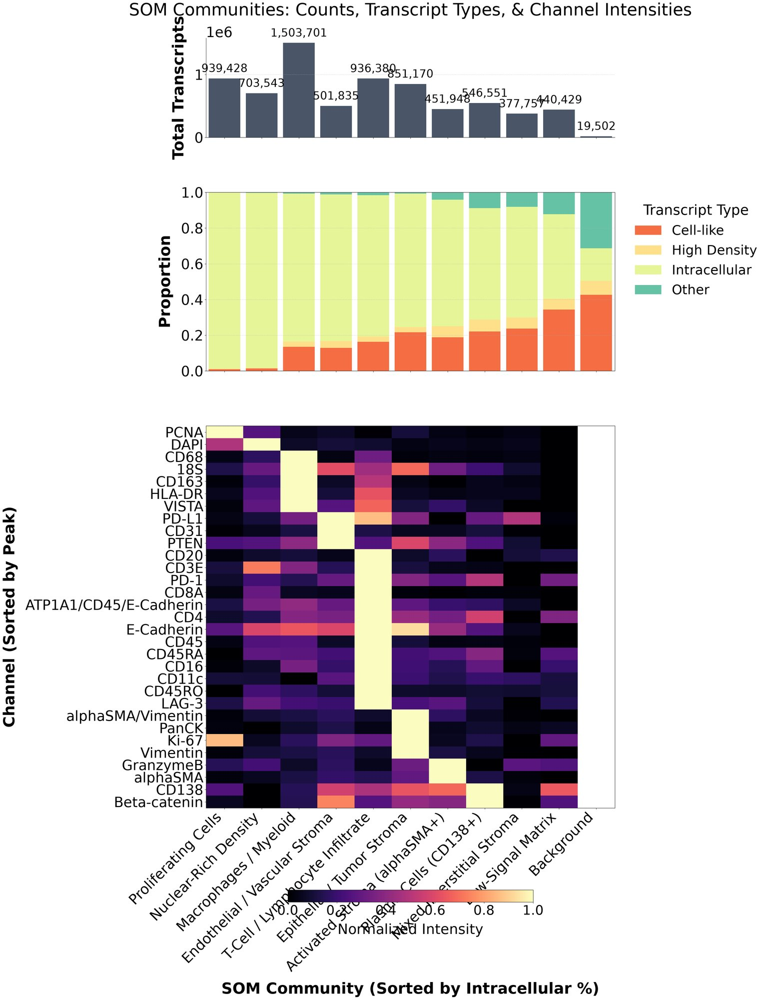

In [37]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# -------------------------------------------------------------------------
# Global Style Settings (Fontsize 42)
# -------------------------------------------------------------------------
FONT_SIZE = 42
plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE + 4,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE - 4,
    "ytick.labelsize": FONT_SIZE - 4,
    "legend.fontsize": FONT_SIZE - 6,
    "legend.title_fontsize": FONT_SIZE - 4,
})


# -------------------------------------------------------------------------
# 1. Recompute Channel Intensities per SOM Community from sdata
# -------------------------------------------------------------------------
intensity_adata = sdata.tables["image_intensity_per_transcript"]

# Convert AnnData .X to DataFrame safely (handles dense or sparse formats)
if hasattr(intensity_adata.X, "toarray"):
    intensity_df = pd.DataFrame(intensity_adata.X.toarray(), columns=intensity_adata.var_names)
else:
    intensity_df = pd.DataFrame(intensity_adata.X, columns=intensity_adata.var_names)

# Assign som_community matching row index
intensity_df["som_community"] = transcripts["som_community"].values

# Compute mean channel intensities per SOM community
df_intensities = intensity_df.groupby("som_community").mean()

# -------------------------------------------------------------------------
# 2. Data Preparation & Sorting
# -------------------------------------------------------------------------
# Compute proportions and total counts per SOM community (INCLUDING 0)
ct_prop = pd.crosstab(
    transcripts["som_community"], 
    transcripts["transcript_type"], 
    normalize="index"
)
totals = transcripts["som_community"].value_counts()

# Sort SOM Communities by descending proportion of 'Intracellular'
sort_col = "Intracellular" if "Intracellular" in ct_prop.columns else ct_prop.columns[0]
ct_prop = ct_prop.sort_values(by=sort_col, ascending=False)

sorted_ids = ct_prop.index
totals = totals.reindex(sorted_ids)

# Filter out background channels
clean_channels = [c for c in df_intensities.columns if "background" not in c.lower()]

# Compute normalized intensities for non-zero clusters (for peak sorting & rendering)
df_intensities_nonzero = df_intensities.loc[df_intensities.index != 0, clean_channels]
norm_intensities_nonzero = (df_intensities_nonzero - df_intensities_nonzero.min()) / (
    df_intensities_nonzero.max() - df_intensities_nonzero.min() + 1e-9
)

# Build a full heatmap matrix aligned with sorted_ids (assigning NaN to cluster 0)
df_heatmap_full = pd.DataFrame(np.nan, index=sorted_ids, columns=clean_channels)
df_heatmap_full.update(norm_intensities_nonzero)
heatmap_data = df_heatmap_full.T

# Sort Channels by where they peak (among non-zero clusters)
non_zero_sorted_ids = [idx for idx in sorted_ids if idx != 0]
peak_community_idx = heatmap_data[non_zero_sorted_ids].idxmax(axis=1).map(lambda x: list(sorted_ids).index(x))
sorted_channels = heatmap_data.assign(peak_idx=peak_community_idx).sort_values("peak_idx", ascending=True).index
heatmap_data = heatmap_data.loc[sorted_channels]

# -------------------------------------------------------------------------
# 3. Synchronized Plotting
# -------------------------------------------------------------------------
x_pos = np.arange(len(sorted_ids))
bar_width = 0.85

fig_width = max(20, len(sorted_ids) * 1.4)
fig_height = max(34, len(sorted_channels) * 0.9 + 18)

fig, (ax_top, ax_mid, ax_bot) = plt.subplots(
    nrows=3, 
    ncols=1, 
    figsize=(fig_width, fig_height), 
    sharex=True, 
    gridspec_kw={"height_ratios": [1, 1.8, 5.5]}
)

# --- TOP PANEL: Total Transcript Counts ---
bars = ax_top.bar(x_pos, totals.values, color="#4A5568", width=bar_width)
ax_top.set_ylabel("Total Transcripts", fontweight="bold", labelpad=20)
ax_top.set_title("SOM Communities: Counts, Transcript Types, & Channel Intensities", pad=30)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)
ax_top.grid(axis="y", linestyle="--", alpha=0.5)

# Annotate numbers on top of bars
for bar in bars:
    height = bar.get_height()
    ax_top.annotate(
        f"{height:,}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center", 
        va="bottom",
        fontsize=FONT_SIZE - 12,
        rotation=35 if len(sorted_ids) > 12 else 0
    )

# --- MIDDLE PANEL: 100% Stacked Bar Plot ---
bottom_val = np.zeros(len(sorted_ids))
colors = sns.color_palette("Spectral", n_colors=len(ct_prop.columns))

for idx, col in enumerate(ct_prop.columns):
    values = ct_prop[col].values
    ax_mid.bar(x_pos, values, bottom=bottom_val, label=col, color=colors[idx], width=bar_width)
    bottom_val += values

ax_mid.set_ylabel("Proportion", fontweight="bold", labelpad=20)
ax_mid.set_ylim(0, 1.0)
ax_mid.legend(title="Transcript Type", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax_mid.grid(axis="y", linestyle="--", alpha=0.5)

# --- BOTTOM PANEL: Channel Intensities Heatmap ---
cmap = plt.cm.magma.copy()
cmap.set_bad(color="white")  # Renders Cluster 0 (NaN column) as neutral white

img = ax_bot.imshow(
    heatmap_data.values, 
    aspect="auto", 
    cmap=cmap, 
    extent=[-0.5, len(sorted_ids) - 0.5, len(sorted_channels) - 0.5, -0.5],
    interpolation="nearest"
)

# Y-Axis (Channels)
ax_bot.set_yticks(np.arange(len(sorted_channels)))
ax_bot.set_yticklabels(sorted_channels)
ax_bot.set_ylabel("Channel (Sorted by Peak)", fontweight="bold", labelpad=20)

# X-Axis (SOM Communities)
ax_bot.set_xticks(x_pos)
ax_bot.set_xticklabels(
    [som_labels.get(x, f"Community {x}") for x in sorted_ids],
    rotation=45,
    ha="right",
)
ax_bot.set_xlabel("SOM Community (Sorted by Intracellular %)", fontweight="bold", labelpad=20)

# Colorbar for Heatmap
cbar = fig.colorbar(img, ax=ax_bot, orientation="horizontal", pad=0.15, shrink=0.6)
cbar.set_label("Normalized Intensity", fontsize=FONT_SIZE - 4, labelpad=15)
cbar.ax.tick_params(labelsize=FONT_SIZE - 6)

plt.savefig(
    os.path.join(saving_path, "som_communities_analysis_magma.pdf"),
    format="pdf",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Top genes per community

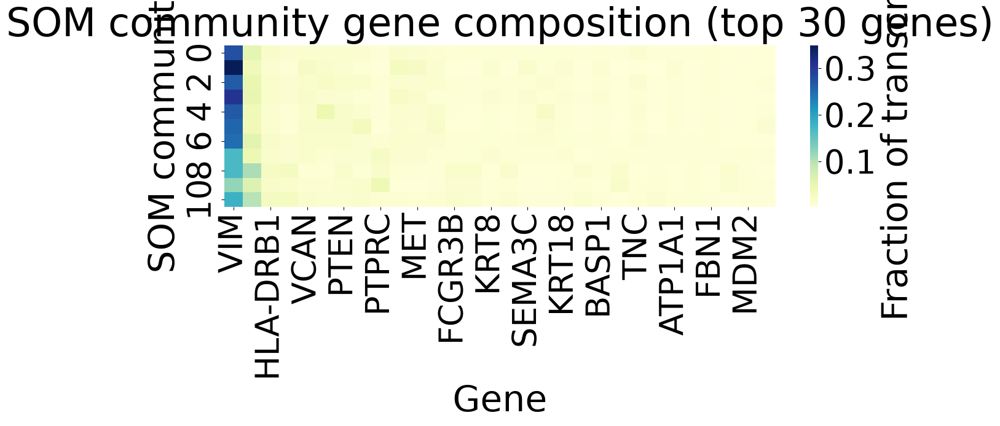

In [38]:
df_counts = pd.crosstab(transcripts["som_community"], transcripts[gene_key])
df_prop = df_counts.div(df_counts.sum(axis=1), axis=0)
top_genes = df_counts.sum(axis=0).sort_values(ascending=False).head(30).index

plt.figure(figsize=(14, 8))
sns.heatmap(df_prop[top_genes], cmap="YlGnBu", cbar_kws={"label": "Fraction of transcripts"})
plt.title("SOM community gene composition (top 30 genes)")
plt.xlabel("Gene")
plt.ylabel("SOM community")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()